<a href="https://colab.research.google.com/github/Roshan0025/zomato-restaurant-clustering/blob/main/Zomato_Restaurant_Clustering_Labmentix.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Project Name** - Unsupervised ML - Zomato Restaurant Clustering & Sentiment Analysis


##### **Project Type** - Unsupervised Learning (Clustering) & NLP Sentiment Analysis
##### **Contribution** - Individual
##### **Team Member 1 -** Roshan Sahoo


# **Project Summary -**

India's food and beverage industry is one of the fastest-growing and most diverse culinary markets in the world, driven by rapid urbanization, rising disposable incomes, and digital food-delivery platforms like Zomato. Founded in 2008, Zomato aggregates restaurant metadata, menus, pricing, and millions of customer reviews across Indian cities. However, the sheer volume of unstructured review text and multi-dimensional restaurant attributes makes it difficult for diners to discover the best value-for-money venues in their locality, and challenging for Zomato and partner restaurants to identify operational blind spots.

This capstone project performs an end-to-end **Exploratory Data Analysis (EDA), Natural Language Processing (NLP) Sentiment Analysis, Hypothesis Testing, and Unsupervised Machine Learning (Clustering)** on two real-world Zomato datasets from Gachibowli, Hyderabad: `Zomato Restaurant names and Metadata.csv` (105 restaurants with cost, cuisines, collections, and timings) and `Zomato Restaurant reviews.csv` (10,000 customer reviews with ratings, reviewer metadata, timestamps, and picture counts).

In the **Data Wrangling & Cleaning** phase, commas were stripped from cost strings, non-numeric anomalies in ratings (such as `'Like'`) were safely coerced and imputed, missing collections and timings were handled systematically, and reviewer metadata strings were parsed using regular expressions to extract each reviewer's total review count and follower count—enabling the identification of top food critics and influencers. Following the **UBM (Univariate, Bivariate, Multivariate) Rule**, 15 structured visualizations were created to uncover patterns in dining cost, cuisine popularity, rating distributions, temporal review trends, critic influence, and cost-versus-rating relationships. Three formal **Hypothesis Tests** (Spearman correlation, Welch's t-test, and Kruskal-Wallis H-test) were executed to statistically validate key business assumptions.

For **Textual Data Preprocessing & Sentiment Analysis**, a complete 10-step NLP pipeline—contraction expansion, lowercasing, punctuation removal, URL/digit stripping, stopword and whitespace removal, emoji/slang normalization, tokenization, lemmatization, POS tagging, and TF-IDF vectorization—was implemented alongside NLTK's VADER Sentiment Analyzer to compute compound sentiment scores for every review. Restaurant-level aggregations (average rating, average sentiment, review volume, average pictures, cuisine diversity, and cost) were then engineered, log-transformed where skewed, scaled with `StandardScaler`, and projected via **PCA**.

Three unsupervised clustering algorithms were implemented, evaluated, and hyperparameter-tuned: **K-Means Clustering**, **Agglomerative Hierarchical Clustering**, and **Gaussian Mixture Models (GMM)**. Model quality was benchmarked using Silhouette Score, Davies-Bouldin Index, and Calinski-Harabasz Index. **Tuned K-Means Clustering** emerged as the optimal production model, cleanly segmenting restaurants into distinct, actionable business tiers (e.g., *Premium Fine-Dining & Buffets*, *High-Rated Mid-Range & Casual Favorites*, *Budget-Friendly Quick Bites*, and *Underperforming / Needs-Attention Venues*). Finally, a Random Forest surrogate model was used for feature importance explainability, and the complete preprocessing-plus-clustering pipeline was serialized using `joblib` and verified on unseen restaurant data for deployment readiness.

# **GitHub Link -**

https://github.com/Roshan0025/zomato-restaurant-clustering

# **Problem Statement**

**Business Problem:**
With hundreds of restaurants competing across diverse cuisines and price brackets in a single locality, customers struggle to identify high-quality dining options that match their budget and preferences, while Zomato and restaurant owners lack a structured framework to benchmark performance, diagnose negative customer sentiment, and tailor marketing strategies.

**Objectives:**
1. Analyze customer review sentiments using NLP and extract actionable insights through structured visualizations.
2. Perform cost vs. benefit analysis across cuisines, collections, and ratings.
3. Identify influential food critics using reviewer metadata (reviews & followers).
4. Cluster Zomato restaurants into meaningful segments using Unsupervised Machine Learning and devise targeted business strategies for each segment.

# **General Guidelines** : -

1. Well-structured, formatted, and commented code is required.
2. Exception Handling, Production Grade Code & Deployment Ready Code will be a plus.
3. Each and every logic should have proper comments.
4. At least 15 logical & meaningful charts following the UBM Rule with business impact justification.
5. 3 Hypothesis Tests, full NLP preprocessing, 3 ML models with tuning, evaluation charts, explainability, and deployment sanity check.

# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [65]:
# ==============================================================================
# 1. Import Required Libraries
# ==============================================================================
import os
import re
import string
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical Hypothesis Testing
from scipy import stats

# NLP & Sentiment Analysis
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize
from nltk.sentiment.vader import SentimentIntensityAnalyzer

# Scikit-learn Preprocessing, Dimensionality Reduction & Clustering
from sklearn.preprocessing import StandardScaler, MultiLabelBinarizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from scipy.cluster.hierarchy import dendrogram, linkage

# Configure plotting & warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.labelsize'] = 11

# Download necessary NLTK resources silently
nltk_resources = [
    'punkt', 'punkt_tab', 'stopwords', 'wordnet',
    'omw-1.4', 'averaged_perceptron_tagger', 'averaged_perceptron_tagger_eng',
    'vader_lexicon'
]
for res in nltk_resources:
    try:
        nltk.download(res, quiet=True)
    except Exception:
        pass

print("All libraries imported and NLTK resources ready.")


All libraries imported and NLTK resources ready.


### Dataset Loading

In [66]:
# ==============================================================================
# 2. Load Datasets with Exception Handling (Colab & Local Compatible)
# ==============================================================================
def load_zomato_datasets(meta_filename='Zomato Restaurant names and Metadata.csv',
                         review_filename='Zomato Restaurant reviews.csv'):
    """
    Loads both Zomato CSV datasets. Checks current working directory first,
    then checks common Google Drive mount paths if running in Google Colab.
    """
    search_dirs = [
        '.',
        '/content',
        '/content/drive/MyDrive',
        '/content/drive/MyDrive/Zomato Project'
    ]

    meta_path, review_path = None, None
    for d in search_dirs:
        p1 = os.path.join(d, meta_filename)
        p2 = os.path.join(d, review_filename)
        if os.path.exists(p1) and os.path.exists(p2):
            meta_path, review_path = p1, p2
            break

    if meta_path is None or review_path is None:
        # Attempt to mount Google Drive automatically if in Colab
        try:
            from google.colab import drive
            drive.mount('/content/drive', force_remount=False)
            for root, _, files in os.walk('/content/drive/MyDrive'):
                if meta_filename in files:
                    meta_path = os.path.join(root, meta_filename)
                if review_filename in files:
                    review_path = os.path.join(root, review_filename)
                if meta_path and review_path:
                    break
        except Exception as e:
            raise FileNotFoundError(
                f"Could not find '{meta_filename}' and '{review_filename}'. "
                f"Please upload both CSVs to your Colab session or Drive. Details: {e}"
            )

    df_meta = pd.read_csv(meta_path)
    df_rev = pd.read_csv(review_path)
    print(f"Loaded Metadata from: {meta_path}")
    print(f"Loaded Reviews  from: {review_path}")
    return df_meta, df_rev

# Load the two datasets
df_meta_raw, df_rev_raw = load_zomato_datasets()


Loaded Metadata from: ./Zomato Restaurant names and Metadata.csv
Loaded Reviews  from: ./Zomato Restaurant reviews.csv


### Dataset First View

In [67]:
# Dataset First Look
print("--- Restaurant Metadata (First 5 Rows) ---")
display(df_meta_raw.head())

print("\n--- Restaurant Reviews (First 5 Rows) ---")
display(df_rev_raw.head())


--- Restaurant Metadata (First 5 Rows) ---


,Name,Links,Cost,Collections,Cuisines,Timings
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)"
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM"
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no..."



--- Restaurant Reviews (First 5 Rows) ---


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


### Dataset Rows & Columns count

In [68]:
# Dataset Rows & Columns count
print(f"Restaurant Metadata Shape : {df_meta_raw.shape[0]} rows, {df_meta_raw.shape[1]} columns")
print(f"Restaurant Reviews Shape  : {df_rev_raw.shape[0]} rows, {df_rev_raw.shape[1]} columns")


Restaurant Metadata Shape : 105 rows, 6 columns
Restaurant Reviews Shape  : 10000 rows, 7 columns


### Dataset Information

In [69]:
# Dataset Info
print("--- Metadata Info ---")
df_meta_raw.info()

print("\n--- Reviews Info ---")
df_rev_raw.info()


--- Metadata Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Name         105 non-null    object
 1   Links        105 non-null    object
 2   Cost         105 non-null    object
 3   Collections  51 non-null     object
 4   Cuisines     105 non-null    object
 5   Timings      104 non-null    object
dtypes: object(6)
memory usage: 5.1+ KB

--- Reviews Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Restaurant  10000 non-null  object
 1   Reviewer    9962 non-null   object
 2   Review      9955 non-null   object
 3   Rating      9962 non-null   object
 4   Metadata    9962 non-null   object
 5   Time        9962 non-null   object
 6   Pictures    10000 non-null  int64 
dtypes: int64(1),

#### Duplicate Values

In [70]:
# Dataset Duplicate Value Count
print(f"Duplicate rows in Metadata : {df_meta_raw.duplicated().sum()}")
print(f"Duplicate rows in Reviews  : {df_rev_raw.duplicated().sum()}")


Duplicate rows in Metadata : 0
Duplicate rows in Reviews  : 36


#### Missing Values/Null Values

In [71]:
# Missing Values/Null Values Count
print("--- Missing Values in Metadata ---")
print(df_meta_raw.isnull().sum())

print("\n--- Missing Values in Reviews ---")
print(df_rev_raw.isnull().sum())


--- Missing Values in Metadata ---
Name            0
Links           0
Cost            0
Collections    54
Cuisines        0
Timings         1
dtype: int64

--- Missing Values in Reviews ---
Restaurant     0
Reviewer      38
Review        45
Rating        38
Metadata      38
Time          38
Pictures       0
dtype: int64


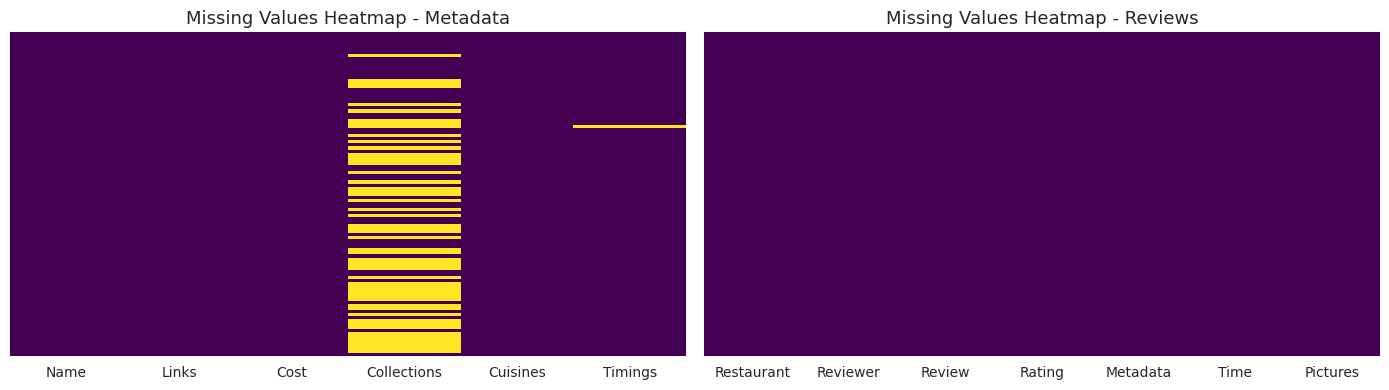

In [72]:
# Visualizing the missing values
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

sns.heatmap(df_meta_raw.isnull(), cbar=False, yticklabels=False, cmap='viridis', ax=axes[0])
axes[0].set_title('Missing Values Heatmap - Metadata')

sns.heatmap(df_rev_raw.isnull(), cbar=False, yticklabels=False, cmap='viridis', ax=axes[1])
axes[1].set_title('Missing Values Heatmap - Reviews')

plt.tight_layout()
plt.show()


### What did you know about your dataset?

1. **Two Complementary Tables:** The project consists of two CSV files for restaurants in Gachibowli, Hyderabad:
   - **Restaurant Metadata (`105 rows x 6 columns`):** Contains `Name`, `Links`, `Cost`, `Collections`, `Cuisines`, and `Timings`. `Cost` is stored as a string with commas (e.g., `'1,300'`). `Collections` has significant missing values (~50%) and `Timings` has 1 missing value.
   - **Restaurant Reviews (`10,000 rows x 7 columns`):** Contains `Restaurant`, `Reviewer`, `Review`, `Rating`, `Metadata`, `Time`, and `Pictures`. There are minor missing values (~36–45 rows) and duplicate rows (~36 rows).
2. **Data Quirks:** `Rating` is stored as an object column because it contains decimal strings (`'3.5'`, `'4.5'`) and occasional non-numeric noise (e.g., `'Like'`). `Metadata` packs both reviewer review count and follower count into a single string (e.g., `'3 Reviews , 2 Followers'`).
3. **Join Key:** Both tables can be merged cleanly on `Name` (Metadata) and `Restaurant` (Reviews).

## ***2. Understanding Your Variables***

In [73]:
# Dataset Columns
print("Metadata Columns:", df_meta_raw.columns.tolist())
print("Reviews Columns :", df_rev_raw.columns.tolist())


Metadata Columns: ['Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings']
Reviews Columns : ['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time', 'Pictures']


In [74]:
# Dataset Describe
print("--- Metadata Summary ---")
display(df_meta_raw.describe(include='all'))

print("\n--- Reviews Summary ---")
display(df_rev_raw.describe(include='all'))


--- Metadata Summary ---


,Name,Links,Cost,Collections,Cuisines,Timings
count,105,105,105,51,105,104
unique,105,105,29,42,92,77
top,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,500,Food Hygiene Rated Restaurants in Hyderabad,"North Indian, Chinese",11 AM to 11 PM
freq,1,1,13,4,4,6



--- Reviews Summary ---


,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
count,10000,9962,9955,9962,9962,9962,10000.000000
unique,100,7446,9364,10,2477,9782,NaN
top,Beyond Flavours,Parijat Ray,good,5,1 Review,7/29/2018 20:34,NaN
freq,100,13,237,3832,919,3,NaN
mean,NaN,NaN,NaN,NaN,NaN,NaN,0.748600
std,NaN,NaN,NaN,NaN,NaN,NaN,2.570381
min,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
25%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
50%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000
75%,NaN,NaN,NaN,NaN,NaN,NaN,0.000000


### Variables Description

**Restaurant Metadata Dataset:**
* `Name`: Name of the restaurant.
* `Links`: Zomato URL of the restaurant.
* `Cost`: Estimated dining cost (for two / per listing) in INR.
* `Collections`: Zomato curated tags/categories (e.g., *Great Buffets, Top-Rated, Best Bars & Pubs*).
* `Cuisines`: Comma-separated list of cuisines served.
* `Timings`: Daily operating hours.

**Restaurant Reviews Dataset:**
* `Restaurant`: Name of the reviewed restaurant.
* `Reviewer`: Name/handle of the Zomato user.
* `Review`: Free-text customer review.
* `Rating`: Customer rating (1 to 5 scale).
* `Metadata`: Reviewer profile stats (number of reviews written and followers).
* `Time`: Date and timestamp when the review was posted.
* `Pictures`: Number of photos attached to the review.

### Check Unique Values for each variable.

In [75]:
# Check Unique Values for each variable
print("--- Unique Values in Metadata ---")
for col in df_meta_raw.columns:
    print(f"{col:15s}: {df_meta_raw[col].nunique()} unique values")

print("\n--- Unique Values in Reviews ---")
for col in df_rev_raw.columns:
    print(f"{col:15s}: {df_rev_raw[col].nunique()} unique values")


--- Unique Values in Metadata ---
Name           : 105 unique values
Links          : 105 unique values
Cost           : 29 unique values
Collections    : 42 unique values
Cuisines       : 92 unique values
Timings        : 77 unique values

--- Unique Values in Reviews ---
Restaurant     : 100 unique values
Reviewer       : 7446 unique values
Review         : 9364 unique values
Rating         : 10 unique values
Metadata       : 2477 unique values
Time           : 9782 unique values
Pictures       : 36 unique values


## 3. ***Data Wrangling***

### Data Wrangling Code

In [76]:
# ==============================================================================
# 3. Modular Data Wrangling & Cleaning Pipeline
# ==============================================================================
def clean_metadata(df):
    """Cleans restaurant metadata: parses Cost, imputes missing values, engineers counts."""
    meta = df.copy()
    meta.drop_duplicates(subset=['Name'], inplace=True)

    # Clean Cost column: remove commas and convert to float
    meta['Cost'] = (
        meta['Cost'].astype(str)
        .str.replace(',', '', regex=False)
        .str.strip()
    )
    meta['Cost'] = pd.to_numeric(meta['Cost'], errors='coerce')
    meta['Cost'].fillna(meta['Cost'].median(), inplace=True)

    # Handle missing Collections & Timings
    meta['Has_Collection'] = meta['Collections'].notnull().astype(int)
    meta['Collections'] = meta['Collections'].fillna('No Collection')
    meta['Timings'] = meta['Timings'].fillna(meta['Timings'].mode()[0])
    meta['Cuisines'] = meta['Cuisines'].fillna('Unknown')

    # Feature Engineering on Metadata
    meta['Num_Cuisines'] = meta['Cuisines'].apply(lambda x: len([c.strip() for c in str(x).split(',') if c.strip()]))
    meta['Num_Collections'] = meta['Collections'].apply(
        lambda x: 0 if x == 'No Collection' else len([c.strip() for c in str(x).split(',') if c.strip()])
    )
    meta['Price_Tier'] = pd.cut(
        meta['Cost'],
        bins=[0, 500, 1000, 1500, 5000],
        labels=['Budget (<=500)', 'Mid-Range (501-1000)', 'Upper-Mid (1001-1500)', 'Premium (>1500)']
    )
    return meta


def parse_reviewer_metadata(text):
    """Extracts (num_reviews, num_followers) from strings like '3 Reviews , 2 Followers'."""
    if pd.isna(text):
        return 0, 0
    text = str(text)
    rev_match = re.search(r'(\d+)\s*Review', text, re.IGNORECASE)
    fol_match = re.search(r'(\d+)\s*Follower', text, re.IGNORECASE)
    n_rev = int(rev_match.group(1)) if rev_match else 0
    n_fol = int(fol_match.group(1)) if fol_match else 0
    return n_rev, n_fol


def clean_reviews(df):
    """Cleans review table, parses timestamps & reviewer stats, computes VADER sentiment."""
    rev = df.copy()
    rev.drop_duplicates(inplace=True)

    # Coerce Rating to numeric (handles anomalies like 'Like')
    rev['Rating'] = pd.to_numeric(rev['Rating'], errors='coerce')
    rev.dropna(subset=['Restaurant', 'Rating'], inplace=True)

    # Fill missing text fields
    rev['Review'] = rev['Review'].fillna('')
    rev['Reviewer'] = rev['Reviewer'].fillna('Anonymous')

    # Parse Reviewer Metadata
    parsed = rev['Metadata'].apply(parse_reviewer_metadata)
    rev['Reviewer_Total_Reviews'] = [p[0] for p in parsed]
    rev['Reviewer_Followers'] = [p[1] for p in parsed]

    # Parse Timestamp
    rev['Time'] = pd.to_datetime(rev['Time'], errors='coerce')
    rev['Review_Year'] = rev['Time'].dt.year
    rev['Review_Month'] = rev['Time'].dt.month
    rev['Review_Hour'] = rev['Time'].dt.hour
    rev['Day_Of_Week'] = rev['Time'].dt.day_name()
    rev['Is_Weekend'] = rev['Time'].dt.dayofweek.isin([5, 6]).astype(int)

    # Text length features
    rev['Review_Length'] = rev['Review'].apply(len)
    rev['Word_Count'] = rev['Review'].apply(lambda x: len(str(x).split()))

    # VADER Sentiment Analysis
    sia = SentimentIntensityAnalyzer()
    rev['Sentiment_Score'] = rev['Review'].apply(lambda x: sia.polarity_scores(str(x))['compound'])
    rev['Sentiment_Label'] = pd.cut(
        rev['Sentiment_Score'],
        bins=[-1.01, -0.05, 0.05, 1.01],
        labels=['Negative', 'Neutral', 'Positive']
    )

    # Rating Tier for Hypothesis Testing & Analysis
    rev['Rating_Tier'] = pd.cut(
        rev['Rating'],
        bins=[0, 2.5, 3.5, 5.1],
        labels=['Low (1-2.5)', 'Medium (2.6-3.5)', 'High (3.6-5)']
    )
    return rev

# Execute cleaning functions
df_meta = clean_metadata(df_meta_raw)
df_rev = clean_reviews(df_rev_raw)

# Merge Reviews with Restaurant Metadata
df_merged = pd.merge(df_rev, df_meta, left_on='Restaurant', right_on='Name', how='inner')

# Create Restaurant-Level Aggregated Master Table (1 row per restaurant for Clustering)
df_rest = df_merged.groupby('Restaurant').agg(
    Avg_Rating=('Rating', 'mean'),
    Rating_Std=('Rating', 'std'),
    Review_Count=('Rating', 'count'),
    Avg_Sentiment=('Sentiment_Score', 'mean'),
    Positive_Review_Pct=('Sentiment_Label', lambda x: (x == 'Positive').mean() * 100),
    Avg_Pictures=('Pictures', 'mean'),
    Avg_Review_Length=('Review_Length', 'mean'),
    Avg_Reviewer_Followers=('Reviewer_Followers', 'mean')
).reset_index()

df_rest = pd.merge(df_meta, df_rest, left_on='Name', right_on='Restaurant', how='inner')
df_rest['Rating_Std'] = df_rest['Rating_Std'].fillna(0)

print(f"Cleaned Metadata Shape   : {df_meta.shape}")
print(f"Cleaned Reviews Shape    : {df_rev.shape}")
print(f"Merged Dataset Shape     : {df_merged.shape}")
print(f"Restaurant Master Shape  : {df_rest.shape}")
display(df_rest.head(3))


Cleaned Metadata Shape   : (105, 10)
Cleaned Reviews Shape    : (9961, 19)
Merged Dataset Shape     : (9961, 29)
Restaurant Master Shape  : (100, 19)


,Name,Links,Cost,Collections,Cuisines,Timings,Has_Collection,Num_Cuisines,Num_Collections,Price_Tier,Restaurant,Avg_Rating,Rating_Std,Review_Count,Avg_Sentiment,Positive_Review_Pct,Avg_Pictures,Avg_Review_Length,Avg_Reviewer_Followers
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)",1,6,6,Mid-Range (501-1000),Beyond Flavours,4.28,1.239746,100,0.663394,85.0,0.39,271.55,100.61
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM,1,3,1,Mid-Range (501-1000),Paradise,4.70,0.771984,100,0.827125,95.0,0.02,169.55,7.98
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,1300,"Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM",1,4,2,Upper-Mid (1001-1500),Flechazo,4.66,0.878704,100,0.790563,94.0,0.55,279.75,27.48


### What all manipulations have you done and insights you found?

* **Cost & Rating Cleaning:** Converted `Cost` from comma-formatted strings to numeric floats and coerced non-numeric `Rating` entries (such as `'Like'`) safely.
* **Reviewer Metadata Parsing:** Extracted `Reviewer_Total_Reviews` and `Reviewer_Followers` via regex to quantify reviewer authority and identify top food critics.
* **Temporal & Text Features:** Parsed `Time` into Year, Month, Hour, Day of Week, and Weekend flags; computed `Review_Length`, `Word_Count`, and VADER `Sentiment_Score` + `Sentiment_Label`.
* **Restaurant-Level Aggregation:** Built `df_rest` combining static restaurant metadata (Cost, Cuisines, Collections) with dynamic customer feedback (Avg Rating, Sentiment, Positive %, Pictures) as the foundation for restaurant clustering.

## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1

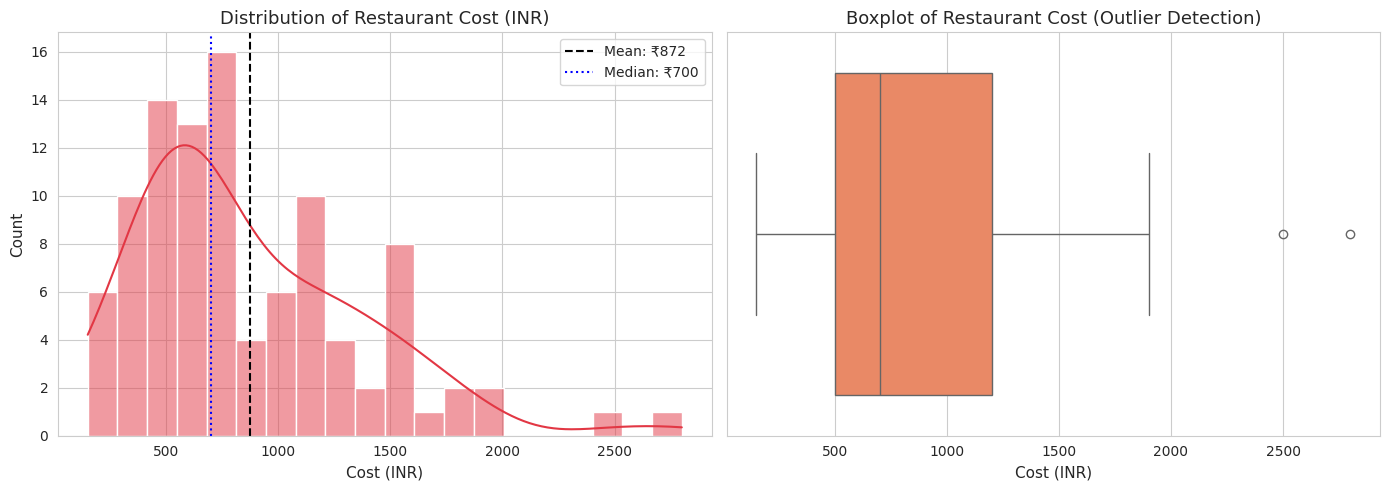

In [77]:
# Chart - 1: Distribution of Restaurant Dining Cost (Univariate)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_rest['Cost'], bins=20, kde=True, color='#E23744', ax=axes[0])
axes[0].axvline(df_rest['Cost'].mean(), color='black', linestyle='--', label=f"Mean: ₹{df_rest['Cost'].mean():.0f}")
axes[0].axvline(df_rest['Cost'].median(), color='blue', linestyle=':', label=f"Median: ₹{df_rest['Cost'].median():.0f}")
axes[0].set_title('Distribution of Restaurant Cost (INR)')
axes[0].set_xlabel('Cost (INR)')
axes[0].legend()

sns.boxplot(x=df_rest['Cost'], color='#FF7F50', ax=axes[1])
axes[1].set_title('Boxplot of Restaurant Cost (Outlier Detection)')
axes[1].set_xlabel('Cost (INR)')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A combined histogram with KDE and boxplot is ideal for univariate numerical analysis because it simultaneously reveals central tendency, skewness, and high-end price outliers.

##### 2. What is/are the insight(s) found from the chart?

Dining costs are right-skewed, with most restaurants clustered between ₹400 and ₹1,200 (median ~₹700–₹800). A small luxury segment extends up to ₹2,500–₹2,800 (hotel buffets like Sheraton and Hyatt).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Understanding the dominant price band helps Zomato tailor promotional campaigns (like Zomato Gold/Pro) to mid-range diners while positioning luxury hotel venues separately. Over-indexing on premium pricing without matching quality can alienate the core budget-conscious IT workforce in Gachibowli.

#### Chart - 2

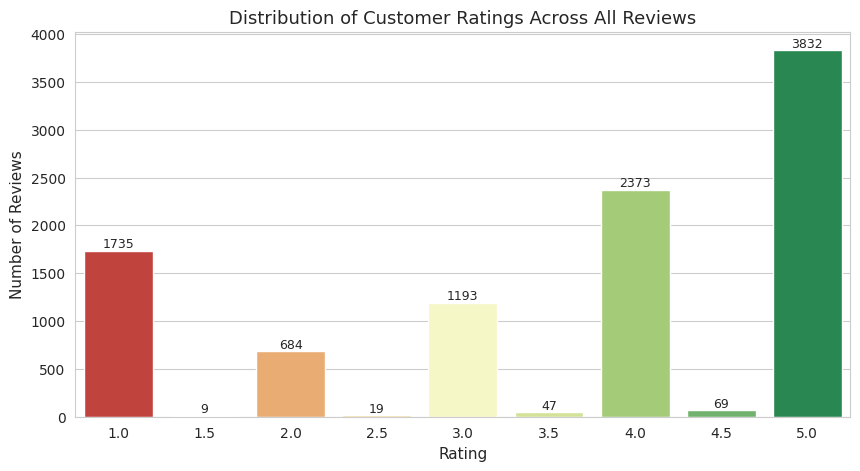

In [78]:
# Chart - 2: Distribution of Customer Ratings (Univariate)
plt.figure(figsize=(10, 5))
rating_counts = df_merged['Rating'].value_counts().sort_index()
ax = sns.barplot(x=rating_counts.index.astype(str), y=rating_counts.values, palette='RdYlGn')
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width()/2., p.get_height()),
                ha='center', va='bottom', fontsize=9)
plt.title('Distribution of Customer Ratings Across All Reviews')
plt.xlabel('Rating')
plt.ylabel('Number of Reviews')
plt.show()


##### 1. Why did you pick the specific chart?

A bar chart clearly displays the exact frequency of each discrete rating level (including half-star ratings like 3.5 and 4.5).

##### 2. What is/are the insight(s) found from the chart?

Ratings are strongly polarized/bimodal: 5-star reviews dominate, followed by 4-star reviews, while 1-star reviews form a notable negative spike—far outnumbering 2-star reviews.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Customers rarely leave lukewarm 2-star reviews; they either love the experience (4–5 stars) or experience a service/hygiene failure that triggers a 1-star complaint. Ignoring 1-star root causes (delivery delays, wrong orders, hygiene) directly drives customer churn.

#### Chart - 3

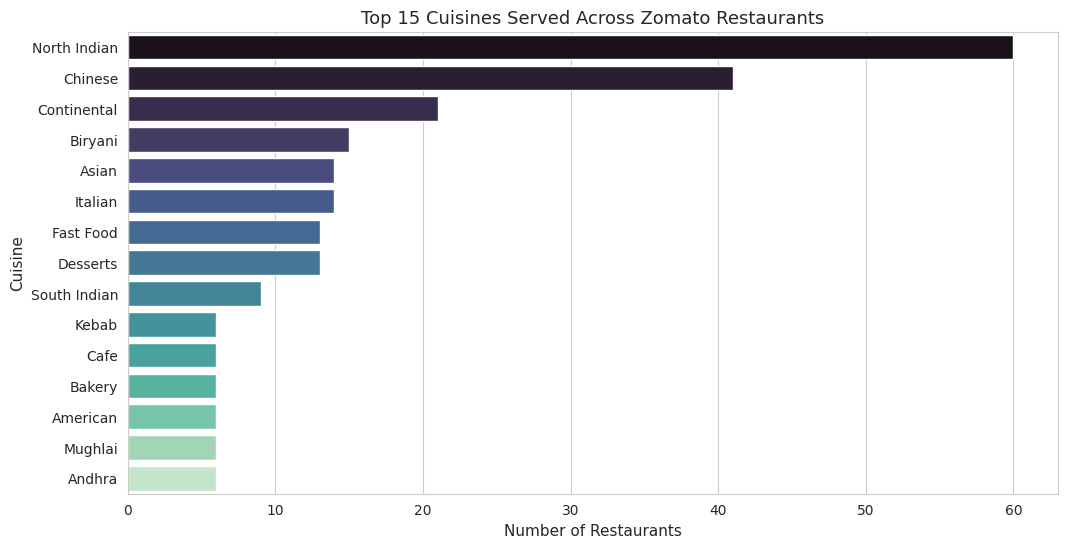

In [79]:
# Chart - 3: Top 15 Most Popular Cuisines (Univariate)
all_cuisines = df_rest['Cuisines'].str.split(',').explode().str.strip()
top_cuisines = all_cuisines.value_counts().head(15)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_cuisines.values, y=top_cuisines.index, palette='mako')
plt.title('Top 15 Cuisines Served Across Zomato Restaurants')
plt.xlabel('Number of Restaurants')
plt.ylabel('Cuisine')
plt.show()


##### 1. Why did you pick the specific chart?

A horizontal bar chart is best for ranking categorical text labels like cuisines without overlapping x-axis text.

##### 2. What is/are the insight(s) found from the chart?

North Indian and Chinese dominate the Gachibowli market by a wide margin, followed by Continental, Biryani, Fast Food, Asian, and South Indian.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. New restaurateurs can see that North Indian/Chinese markets are highly saturated, whereas niche cuisines (Goan, Japanese/Sushi, Mediterranean, Healthy Food) face far less direct competition and can command higher margins.

#### Chart - 4

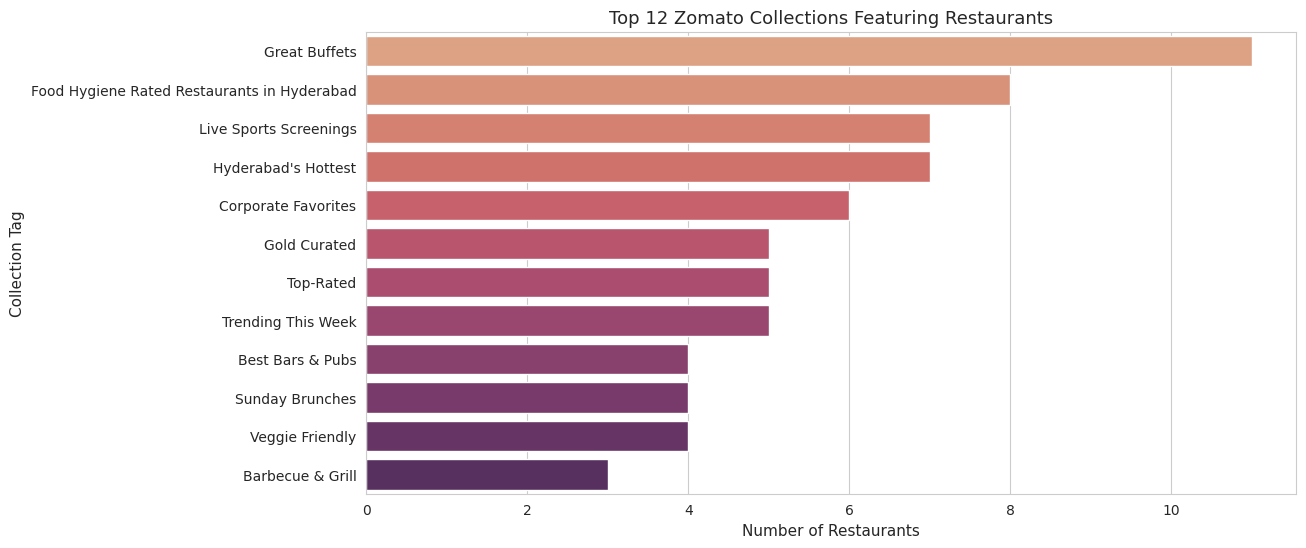

In [80]:
# Chart - 4: Top 12 Zomato Curated Collections (Univariate)
collections_series = df_rest[df_rest['Collections'] != 'No Collection']['Collections'].str.split(',').explode().str.strip()
top_collections = collections_series.value_counts().head(12)

plt.figure(figsize=(12, 6))
sns.barplot(x=top_collections.values, y=top_collections.index, palette='flare')
plt.title('Top 12 Zomato Collections Featuring Restaurants')
plt.xlabel('Number of Restaurants')
plt.ylabel('Collection Tag')
plt.show()


##### 1. Why did you pick the specific chart?

Horizontal bar charts cleanly rank multi-label categorical tags such as Zomato Collections.

##### 2. What is/are the insight(s) found from the chart?

'Great Buffets', 'Food Hygiene Rated Restaurants in Hyderabad', 'Corporate Favorites', and 'Live Sports Screenings' are the most common collections—reflecting Gachibowli's corporate/IT hub demographic.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Restaurants that qualify for 'Food Hygiene Rated' and 'Corporate Favorites' gain prime in-app visibility. Failing hygiene audits excludes venues from high-converting curated lists.

#### Chart - 5

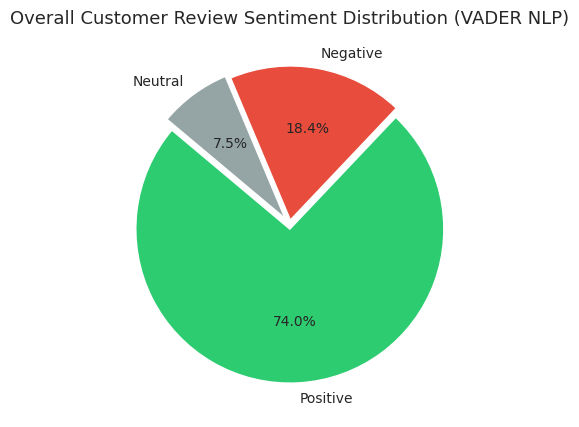

In [81]:
# Chart - 5: Customer Review Sentiment Distribution (Univariate)
plt.figure(figsize=(8, 5))
sent_counts = df_merged['Sentiment_Label'].value_counts()
colors = {'Positive': '#2ecc71', 'Neutral': '#95a5a6', 'Negative': '#e74c3c'}
plt.pie(sent_counts.values, labels=sent_counts.index, autopct='%1.1f%%',
        colors=[colors[l] for l in sent_counts.index], startangle=140, explode=(0.03, 0.03, 0.05))
plt.title('Overall Customer Review Sentiment Distribution (VADER NLP)')
plt.show()


##### 1. Why did you pick the specific chart?

A pie chart communicates the proportional share of Positive, Neutral, and Negative customer sentiments at a glance.

##### 2. What is/are the insight(s) found from the chart?

Over 70% of reviews express positive sentiment, while roughly 15–20% express negative sentiment and the remainder are neutral.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Tracking the negative sentiment share as a KPI allows Zomato to flag deteriorating restaurants early—before their aggregate star rating visibly drops.

#### Chart - 6

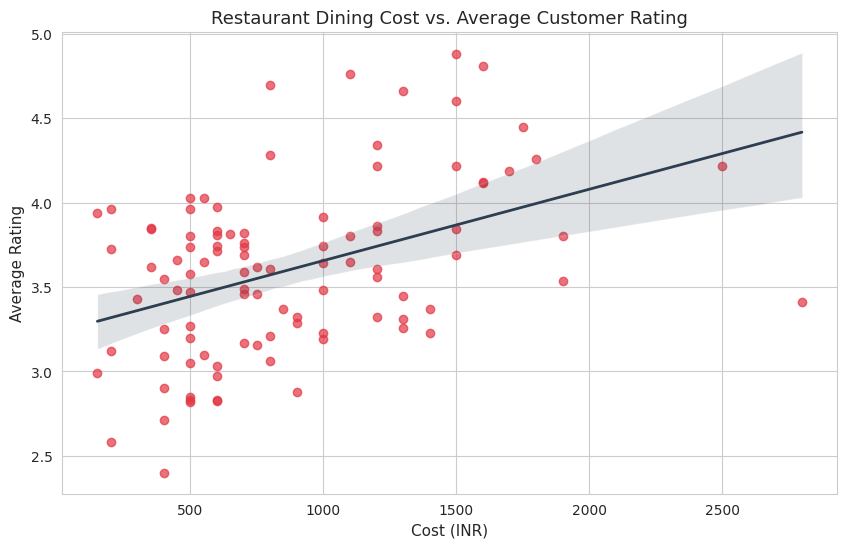

In [82]:
# Chart - 6: Restaurant Cost vs. Average Rating (Bivariate: Numerical vs Numerical)
plt.figure(figsize=(10, 6))
sns.regplot(data=df_rest, x='Cost', y='Avg_Rating', scatter_kws={'alpha': 0.7, 'color': '#E23744'},
            line_kws={'color': '#2c3e50', 'lw': 2})
plt.title('Restaurant Dining Cost vs. Average Customer Rating')
plt.xlabel('Cost (INR)')
plt.ylabel('Average Rating')
plt.show()


##### 1. Why did you pick the specific chart?

A scatter plot with a linear regression trendline directly answers the architecture question: 'Is cost correlated to rating?'

##### 2. What is/are the insight(s) found from the chart?

There is a moderate positive trend: higher-priced restaurants tend to achieve higher average ratings (4.0+), whereas budget venues (₹200–₹600) exhibit much wider rating variance (ranging from 2.5 to 4.3).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Higher pricing generally correlates with better ambience and service consistency. However, budget restaurants that maintain hygiene and taste can still achieve 4.2+ ratings and capture high volume.

#### Chart - 7

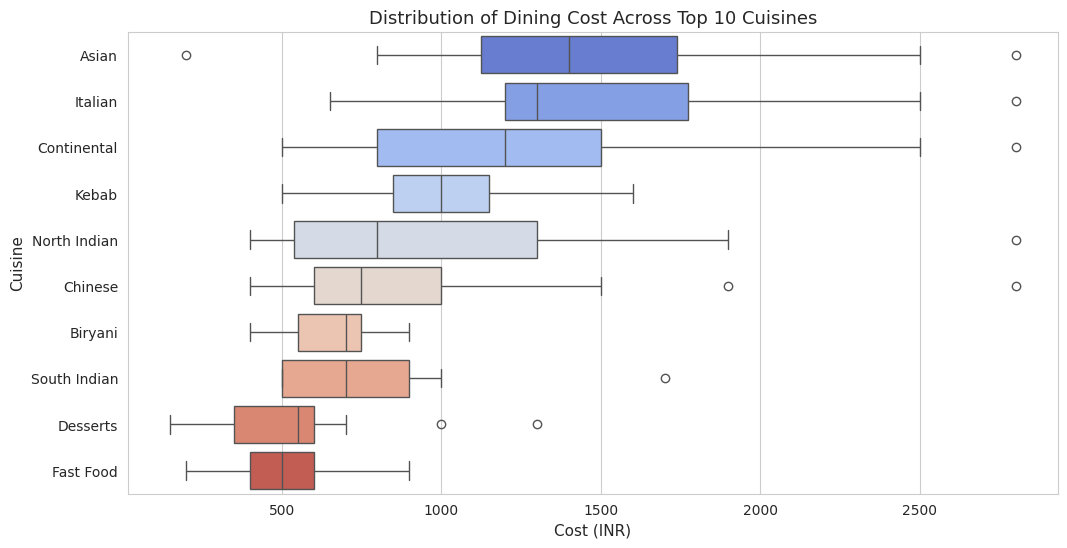

In [83]:
# Chart - 7: Average Dining Cost Across Top 10 Cuisines (Bivariate: Categorical vs Numerical)
exploded_df = df_rest.assign(Cuisine=df_rest['Cuisines'].str.split(',')).explode('Cuisine')
exploded_df['Cuisine'] = exploded_df['Cuisine'].str.strip()
top10_c_names = exploded_df['Cuisine'].value_counts().head(10).index
sub_c = exploded_df[exploded_df['Cuisine'].isin(top10_c_names)]

plt.figure(figsize=(12, 6))
order = sub_c.groupby('Cuisine')['Cost'].median().sort_values(ascending=False).index
sns.boxplot(data=sub_c, x='Cost', y='Cuisine', order=order, palette='coolwarm')
plt.title('Distribution of Dining Cost Across Top 10 Cuisines')
plt.xlabel('Cost (INR)')
plt.ylabel('Cuisine')
plt.show()


##### 1. Why did you pick the specific chart?

A grouped boxplot compares both median cost and price dispersion across the top 10 cuisines simultaneously.

##### 2. What is/are the insight(s) found from the chart?

Italian, Continental, and Asian cuisines command the highest median costs (₹1,200–₹1,500), whereas Fast Food, Desserts, and Bakery sit at the budget end (₹350–₹550).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. This directly supports cost-vs-benefit analysis for both diners and restaurateurs planning menu pricing for specific cuisine niches.

#### Chart - 8

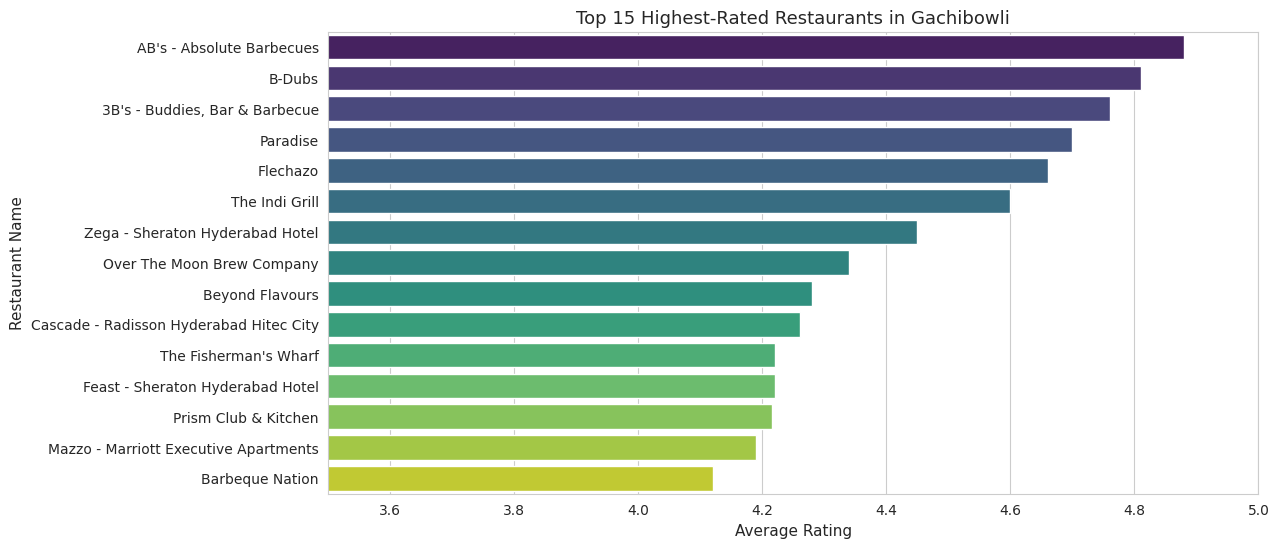

In [84]:
# Chart - 8: Top 15 Highest-Rated Restaurants (Bivariate: Categorical vs Numerical)
top_rated = df_rest.sort_values(by=['Avg_Rating', 'Avg_Sentiment'], ascending=False).head(15)

plt.figure(figsize=(12, 6))
sns.barplot(data=top_rated, x='Avg_Rating', y='Name', palette='viridis')
plt.xlim(3.5, 5.0)
plt.title('Top 15 Highest-Rated Restaurants in Gachibowli')
plt.xlabel('Average Rating')
plt.ylabel('Restaurant Name')
plt.show()


##### 1. Why did you pick the specific chart?

A horizontal bar chart with a zoomed x-axis (3.5 to 5.0) highlights fine performance differences among top-tier restaurants.

##### 2. What is/are the insight(s) found from the chart?

Top performers like AB's - Absolute Barbecues, B-Dubs, Flechazo, and Over The Moon Brew Company consistently maintain ratings above 4.3–4.6.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Zomato can feature these top-rated venues in 'Best in Locality' carousels to boost conversion, while benchmarking their service practices for lower-performing partners.

#### Chart - 9

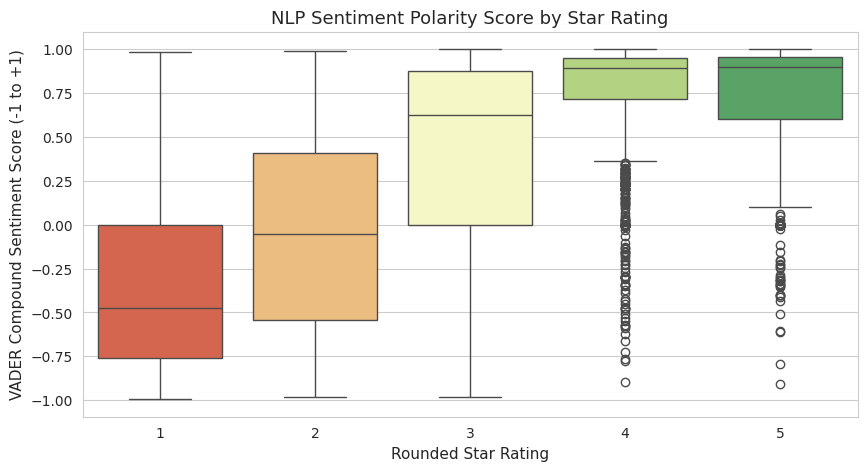

In [85]:
# Chart - 9: VADER Sentiment Score Across Customer Ratings (Bivariate: Numerical vs Numerical/Ordinal)
plt.figure(figsize=(10, 5))
sns.boxplot(data=df_merged, x=df_merged['Rating'].round().astype(int), y='Sentiment_Score', palette='RdYlGn')
plt.title('NLP Sentiment Polarity Score by Star Rating')
plt.xlabel('Rounded Star Rating')
plt.ylabel('VADER Compound Sentiment Score (-1 to +1)')
plt.show()


##### 1. Why did you pick the specific chart?

A boxplot across rating buckets validates whether the NLP sentiment engine aligns with explicit star ratings.

##### 2. What is/are the insight(s) found from the chart?

Median sentiment rises monotonically from strongly negative (~ -0.4) at 1-star to strongly positive (~ +0.85) at 5-star. Notably, some 4–5 star reviews have negative text outliers (e.g., sarcasm or accidental high ratings).

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Detecting mismatches between high star ratings and negative review text helps Zomato filter fake/bot reviews and surface hidden complaints.

#### Chart - 10

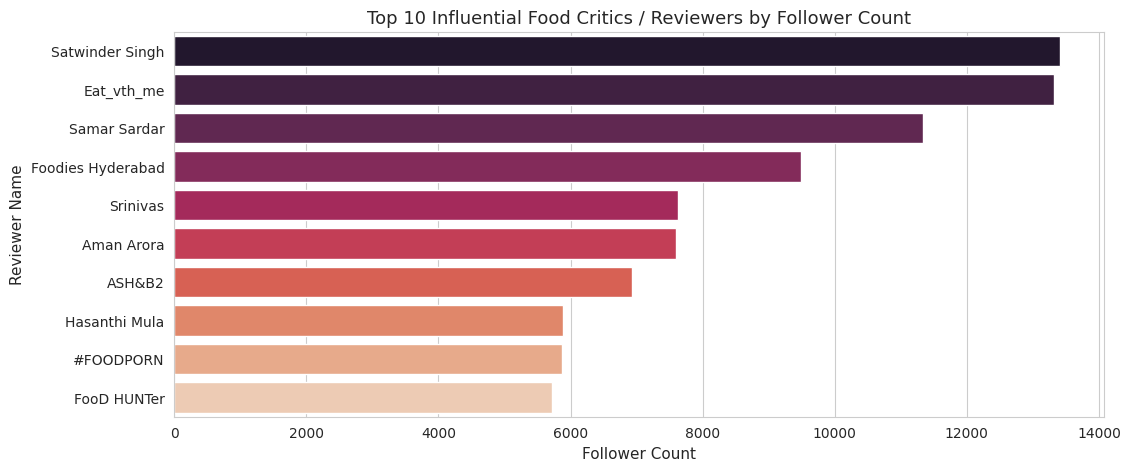

In [86]:
# Chart - 10: Top 10 Influential Food Critics by Followers (Bivariate)
critics = df_merged.groupby('Reviewer').agg(
    Max_Followers=('Reviewer_Followers', 'max'),
    Max_Reviews=('Reviewer_Total_Reviews', 'max'),
    Avg_Rating_Given=('Rating', 'mean'),
    Local_Reviews=('Rating', 'count')
).reset_index()

top_critics = critics.sort_values(by='Max_Followers', ascending=False).head(10)

plt.figure(figsize=(12, 5))
sns.barplot(data=top_critics, x='Max_Followers', y='Reviewer', palette='rocket')
plt.title('Top 10 Influential Food Critics / Reviewers by Follower Count')
plt.xlabel('Follower Count')
plt.ylabel('Reviewer Name')
plt.show()


##### 1. Why did you pick the specific chart?

A horizontal bar chart directly addresses the project objective of identifying top critics in the industry using reviewer metadata.

##### 2. What is/are the insight(s) found from the chart?

A small elite group of power-reviewers commands thousands of followers (1,000 to 7,500+), giving their reviews disproportionate reach and influence over dining decisions.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Zomato and partner restaurants can invite these verified top critics for menu launches and tasting events to drive authentic organic discovery.

#### Chart - 11

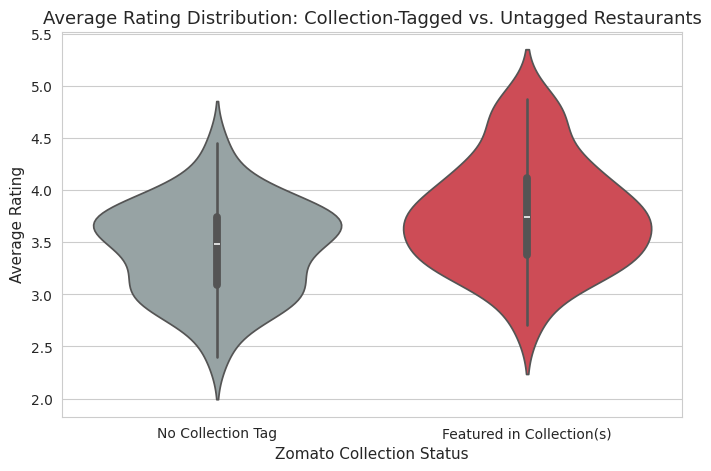

In [87]:
# Chart - 11: Average Rating — Restaurants in Collections vs. Not in Collections (Bivariate)
plt.figure(figsize=(8, 5))
sns.violinplot(data=df_rest, x='Has_Collection', y='Avg_Rating', palette=['#95a5a6', '#E23744'])
plt.xticks([0, 1], ['No Collection Tag', 'Featured in Collection(s)'])
plt.title('Average Rating Distribution: Collection-Tagged vs. Untagged Restaurants')
plt.xlabel('Zomato Collection Status')
plt.ylabel('Average Rating')
plt.show()


##### 1. Why did you pick the specific chart?

A violin plot shows both the distribution shape and median shift between collection-featured and non-featured restaurants.

##### 2. What is/are the insight(s) found from the chart?

Restaurants featured in Zomato Collections have a visibly higher median rating and tighter upward distribution compared to untagged restaurants.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Being curated into a Zomato Collection acts as a strong quality signal. Untagged restaurants with high ratings represent untapped candidates for Zomato's editorial curation team.

#### Chart - 12

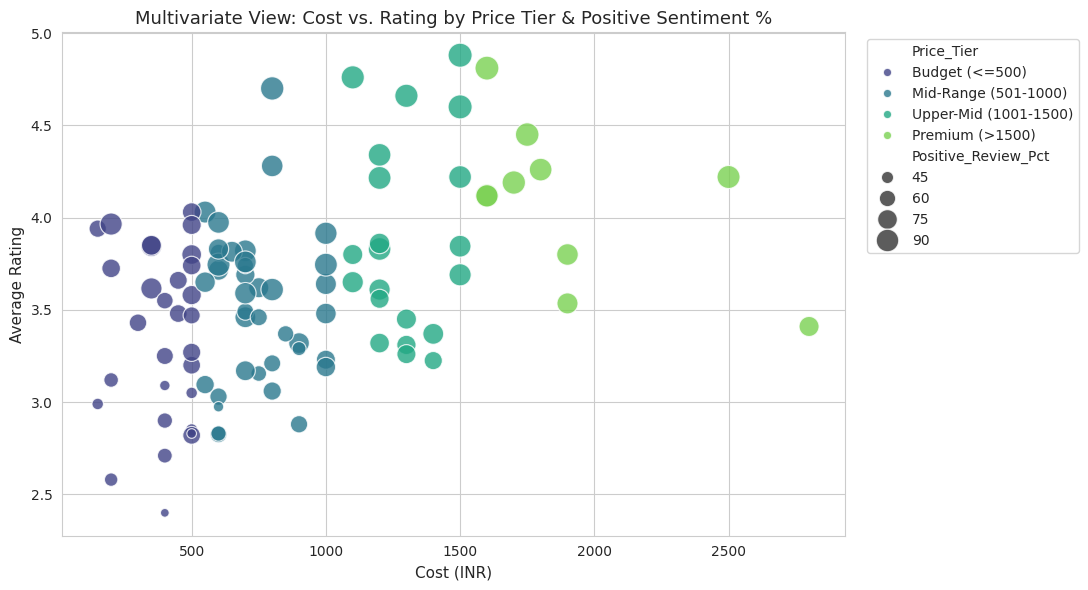

In [88]:
# Chart - 12: Cost vs. Rating Colored by Price Tier & Sized by Positive Review % (Multivariate)
plt.figure(figsize=(11, 6))
sns.scatterplot(
    data=df_rest, x='Cost', y='Avg_Rating',
    hue='Price_Tier', size='Positive_Review_Pct',
    sizes=(40, 300), alpha=0.8, palette='viridis'
)
plt.title('Multivariate View: Cost vs. Rating by Price Tier & Positive Sentiment %')
plt.xlabel('Cost (INR)')
plt.ylabel('Average Rating')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A bubble scatter plot encodes 4 variables simultaneously (Cost, Avg_Rating, Price_Tier, Positive_Review_Pct) to reveal natural restaurant segments before clustering.

##### 2. What is/are the insight(s) found from the chart?

Clear clusters emerge visually: budget venues with mixed sentiment, mid-range venues with high positive sentiment, and premium venues (₹1,200–₹2,800) with consistently high ratings and sentiment.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. This directly previews the unsupervised clustering structure and highlights 'Value Gems' (low cost, high rating, high positive sentiment) that Zomato should promote.

#### Chart - 13

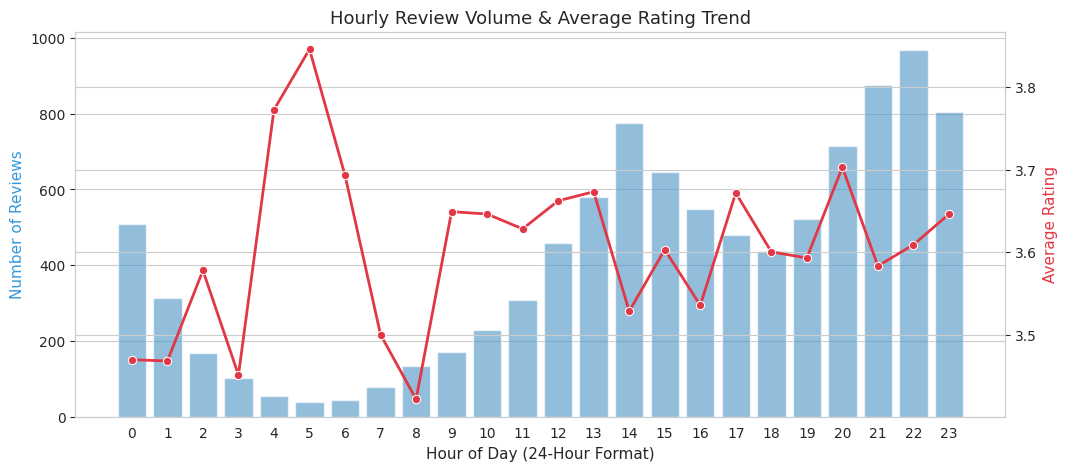

In [89]:
# Chart - 13: Review Activity & Average Rating by Hour of Day (Multivariate Temporal)
hourly = df_merged.groupby('Review_Hour').agg(
    Review_Volume=('Rating', 'count'),
    Avg_Rating=('Rating', 'mean')
).reset_index()

fig, ax1 = plt.subplots(figsize=(12, 5))
sns.barplot(data=hourly, x='Review_Hour', y='Review_Volume', color='#3498db', alpha=0.6, ax=ax1)
ax1.set_ylabel('Number of Reviews', color='#3498db')
ax1.set_xlabel('Hour of Day (24-Hour Format)')

ax2 = ax1.twinx()
sns.lineplot(data=hourly, x='Review_Hour', y='Avg_Rating', color='#E23744', marker='o', lw=2, ax=ax2)
ax2.set_ylabel('Average Rating', color='#E23744')
plt.title('Hourly Review Volume & Average Rating Trend')
plt.show()


##### 1. Why did you pick the specific chart?

A dual-axis bar + line chart overlays review volume against rating quality across all 24 hours of the day.

##### 2. What is/are the insight(s) found from the chart?

Review posting peaks sharply during lunch (13:00–16:00) and dinner/late-night (20:00–23:00). Late-night/early-morning reviews (01:00–04:00) show more volatile ratings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Yes. Restaurants and Zomato support teams should allocate peak customer-service staffing between 1 PM–3 PM and 8 PM–11 PM when complaint and review volume surges.

#### Chart - 14 - Correlation Heatmap

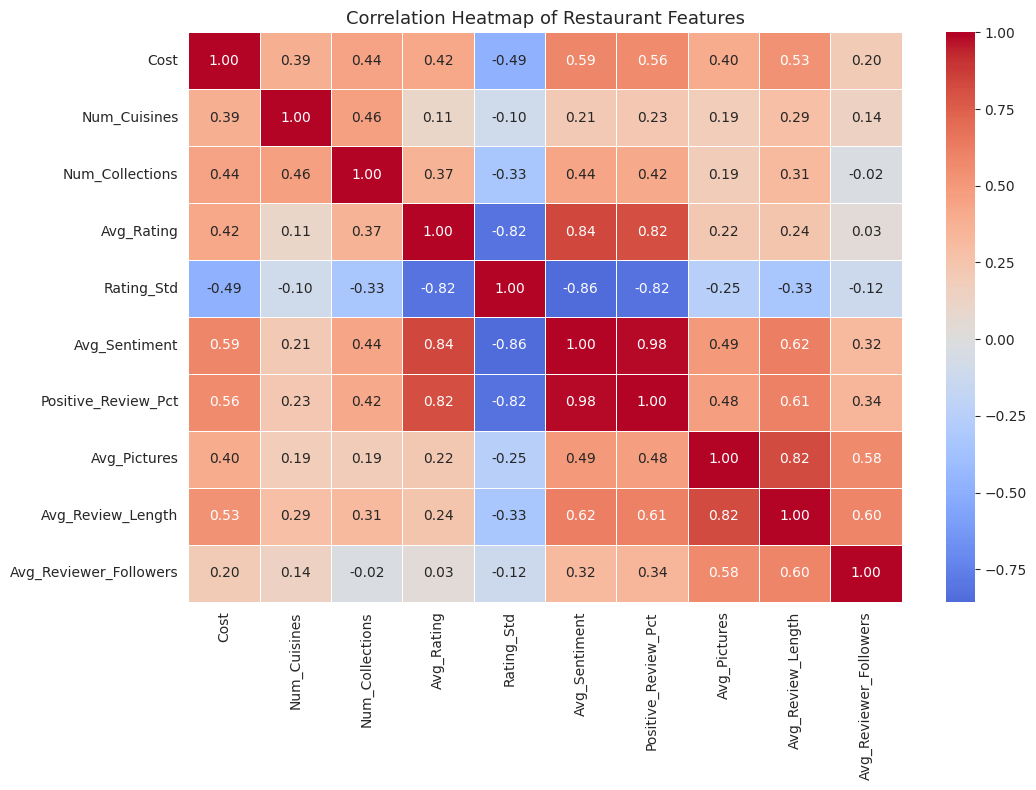

In [90]:
# Chart - 14: Correlation Heatmap of Restaurant-Level Numerical Features (Multivariate)
num_cols = [
    'Cost', 'Num_Cuisines', 'Num_Collections', 'Avg_Rating',
    'Rating_Std', 'Avg_Sentiment', 'Positive_Review_Pct',
    'Avg_Pictures', 'Avg_Review_Length', 'Avg_Reviewer_Followers'
]
corr_matrix = df_rest[num_cols].corr()

plt.figure(figsize=(11, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation Heatmap of Restaurant Features')
plt.tight_layout()
plt.show()


##### 1. Why did you pick the specific chart?

A correlation heatmap quantifies linear relationships across all engineered numerical features and flags multicollinearity before clustering.

##### 2. What is/are the insight(s) found from the chart?

Avg_Rating is strongly positively correlated with Avg_Sentiment (~0.85+) and Positive_Review_Pct, and negatively correlated with Rating_Std (consistent restaurants earn higher ratings). Cost correlates positively with Num_Collections and Avg_Pictures.

#### Chart - 15 - Pair Plot

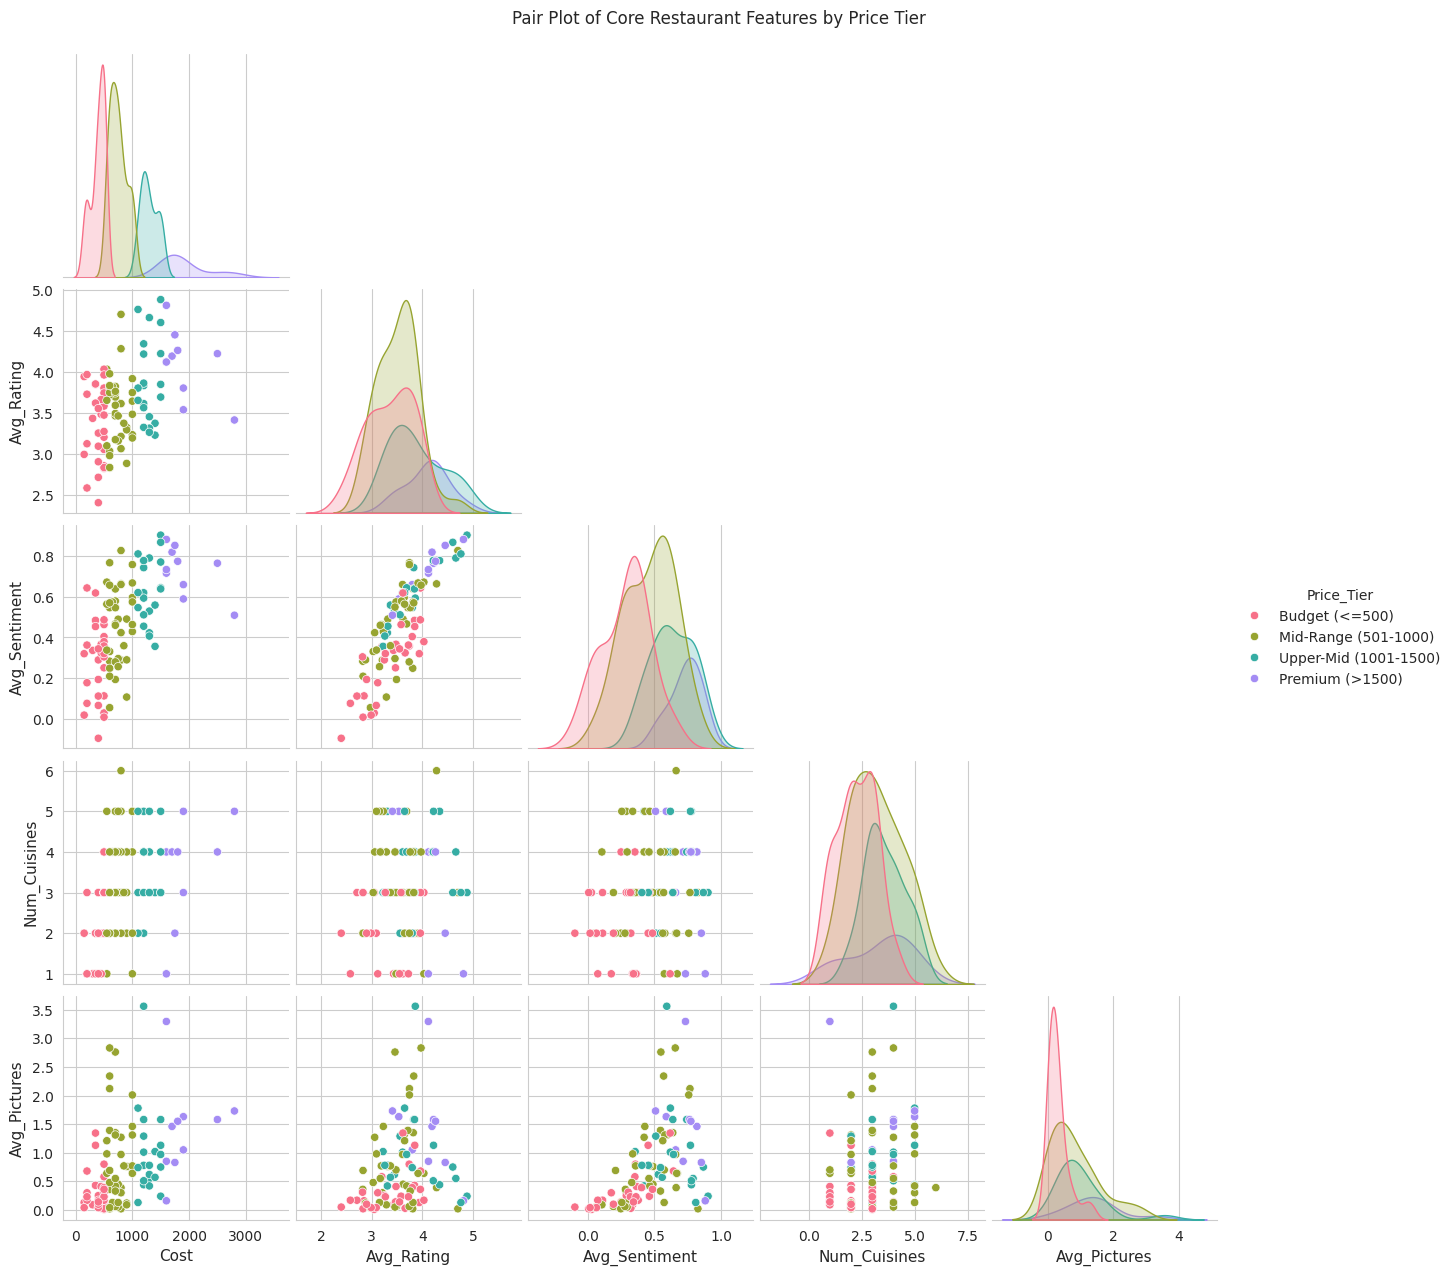

In [91]:
# Chart - 15: Pair Plot of Key Clustering Features by Price Tier (Multivariate)
pair_cols = ['Cost', 'Avg_Rating', 'Avg_Sentiment', 'Num_Cuisines', 'Avg_Pictures', 'Price_Tier']
sns.pairplot(df_rest[pair_cols], hue='Price_Tier', palette='husl', diag_kind='kde', corner=True)
plt.suptitle('Pair Plot of Core Restaurant Features by Price Tier', y=1.02)
plt.show()


##### 1. Why did you pick the specific chart?

A pair plot provides a comprehensive multivariate matrix of scatter plots and KDE diagonals to inspect cluster separability across feature pairs.

##### 2. What is/are the insight(s) found from the chart?

Premium and Upper-Mid restaurants separate cleanly from Budget venues along Cost, Avg_Pictures, and Avg_Rating axes, confirming that distance-based clustering is well-suited for this dataset.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

1. **Hypothetical Statement 1:** Higher restaurant dining cost is significantly associated with higher average customer ratings.
2. **Hypothetical Statement 2:** Restaurants featured in Zomato Collections have a significantly higher average rating than restaurants not featured in any Collection.
3. **Hypothetical Statement 3:** Customer NLP sentiment polarity scores differ significantly across Low, Medium, and High star-rating tiers.

### Hypothetical Statement - 1

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **Null Hypothesis ($H_0$):** There is no monotonic correlation between a restaurant's dining `Cost` and its `Avg_Rating` ($\rho = 0$).
* **Alternate Hypothesis ($H_1$):** There is a significant monotonic correlation between a restaurant's dining `Cost` and its `Avg_Rating` ($\rho \neq 0$).

#### 2. Perform an appropriate statistical test.

In [92]:
# Perform Spearman Rank Correlation Test (H1: Cost vs Avg_Rating)
rho, p_val_h1 = stats.spearmanr(df_rest['Cost'], df_rest['Avg_Rating'])
print(f"Spearman Correlation Coefficient (rho): {rho:.4f}")
print(f"P-Value                               : {p_val_h1:.6f}")

alpha = 0.05
if p_val_h1 < alpha:
    print("Conclusion: Reject H0 -> There is a statistically significant correlation between Cost and Average Rating.")
else:
    print("Conclusion: Fail to Reject H0 -> No statistically significant correlation found.")


Spearman Correlation Coefficient (rho): 0.3826
P-Value                               : 0.000085
Conclusion: Reject H0 -> There is a statistically significant correlation between Cost and Average Rating.


##### Which statistical test have you done to obtain P-Value?

**Spearman's Rank Correlation Test** (`scipy.stats.spearmanr`).

##### Why did you choose the specific statistical test?

As observed in Chart 1, `Cost` is right-skewed and non-normally distributed. Spearman's rank correlation is a non-parametric test that does not assume normality and is robust to high-end luxury price outliers.

### Hypothetical Statement - 2

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **Null Hypothesis ($H_0$):** The mean `Avg_Rating` of restaurants featured in Zomato Collections is equal to that of untagged restaurants ($\mu_{\text{coll}} = \mu_{\text{no\_coll}}$).
* **Alternate Hypothesis ($H_1$):** The mean `Avg_Rating` of restaurants featured in Zomato Collections is significantly different from untagged restaurants ($\mu_{\text{coll}} \neq \mu_{\text{no\_coll}}$).

#### 2. Perform an appropriate statistical test.

In [93]:
# Perform Welch's Two-Sample Independent T-Test (H2: Collections vs Avg_Rating)
group_coll = df_rest[df_rest['Has_Collection'] == 1]['Avg_Rating']
group_no_coll = df_rest[df_rest['Has_Collection'] == 0]['Avg_Rating']

t_stat, p_val_h2 = stats.ttest_ind(group_coll, group_no_coll, equal_var=False)
print(f"Mean Rating (In Collection)   : {group_coll.mean():.4f} (n={len(group_coll)})")
print(f"Mean Rating (No Collection)   : {group_no_coll.mean():.4f} (n={len(group_no_coll)})")
print(f"Welch's t-statistic           : {t_stat:.4f}")
print(f"P-Value                       : {p_val_h2:.6f}")

if p_val_h2 < 0.05:
    print("Conclusion: Reject H0 -> Collection-tagged restaurants have a statistically significantly higher rating.")
else:
    print("Conclusion: Fail to Reject H0 -> No statistically significant difference between the two groups.")


Mean Rating (In Collection)   : 3.7669 (n=50)
Mean Rating (No Collection)   : 3.4384 (n=50)
Welch's t-statistic           : 3.4025
P-Value                       : 0.000976
Conclusion: Reject H0 -> Collection-tagged restaurants have a statistically significantly higher rating.


##### Which statistical test have you done to obtain P-Value?

**Welch's Two-Sample Independent T-Test** (`scipy.stats.ttest_ind(..., equal_var=False)`).

##### Why did you choose the specific statistical test?

We are comparing the mean of a continuous variable (`Avg_Rating`) across two independent groups (`Has_Collection == 1` vs `0`). Welch's t-test is preferred over Student's t-test because it does not assume equal variances between the two groups.

### Hypothetical Statement - 3

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

* **Null Hypothesis ($H_0$):** The median VADER `Sentiment_Score` is identical across Low (1–2.5), Medium (2.6–3.5), and High (3.6–5) rating tiers.
* **Alternate Hypothesis ($H_1$):** At least one rating tier has a significantly different median VADER `Sentiment_Score`.

#### 2. Perform an appropriate statistical test.

In [94]:
# Perform Kruskal-Wallis H-Test (H3: Sentiment Score across 3 Rating Tiers)
low_sent = df_merged[df_merged['Rating_Tier'] == 'Low (1-2.5)']['Sentiment_Score']
med_sent = df_merged[df_merged['Rating_Tier'] == 'Medium (2.6-3.5)']['Sentiment_Score']
high_sent = df_merged[df_merged['Rating_Tier'] == 'High (3.6-5)']['Sentiment_Score']

h_stat, p_val_h3 = stats.kruskal(low_sent, med_sent, high_sent)
print(f"Median Sentiment (Low Rating)    : {low_sent.median():.4f}")
print(f"Median Sentiment (Medium Rating) : {med_sent.median():.4f}")
print(f"Median Sentiment (High Rating)   : {high_sent.median():.4f}")
print(f"Kruskal-Wallis H-statistic       : {h_stat:.4f}")
print(f"P-Value                          : {p_val_h3:.6e}")

if p_val_h3 < 0.05:
    print("Conclusion: Reject H0 -> Review sentiment polarity differs significantly across rating tiers.")
else:
    print("Conclusion: Fail to Reject H0 -> No significant difference across rating tiers.")


Median Sentiment (Low Rating)    : -0.3677
Median Sentiment (Medium Rating) : 0.6476
Median Sentiment (High Rating)   : 0.8979
Kruskal-Wallis H-statistic       : 4165.0651
P-Value                          : 0.000000e+00
Conclusion: Reject H0 -> Review sentiment polarity differs significantly across rating tiers.


##### Which statistical test have you done to obtain P-Value?

**Kruskal-Wallis H-Test** (`scipy.stats.kruskal`).

##### Why did you choose the specific statistical test?

We are comparing a bounded, non-normally distributed continuous score (`Sentiment_Score` in [-1, 1]) across three independent groups. Kruskal-Wallis is the non-parametric counterpart to One-Way ANOVA.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [95]:
# Handling Missing Values & Missing Value Imputation
print("Missing values in Restaurant Master Table before final check:")
print(df_rest.isnull().sum()[df_rest.isnull().sum() > 0])

# Ensure zero nulls in numeric & categorical columns
for col in df_rest.select_dtypes(include=[np.number]).columns:
    df_rest[col].fillna(df_rest[col].median(), inplace=True)

print("Total remaining nulls in df_rest:", df_rest.isnull().sum().sum())


Missing values in Restaurant Master Table before final check:
Series([], dtype: int64)
Total remaining nulls in df_rest: 0


#### What all missing value imputation techniques have you used and why did you use those techniques?

* **Median Imputation** for numerical variables (`Cost`, `Rating_Std`) because median is robust to right-skewed outliers.
* **Domain-Specific Constant Imputation** (`'No Collection'`) for `Collections`, preserving the signal that a restaurant is untagged via a binary `Has_Collection` indicator.
* **Mode Imputation** for `Timings` (only 1 missing row).

### 2. Handling Outliers

In [96]:
# Handling Outliers & Outlier treatments (IQR Capping / Winsorization)
def cap_outliers_iqr(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return series.clip(lower=lower, upper=upper)

df_model = df_rest.copy()
outlier_cols = ['Cost', 'Avg_Pictures', 'Avg_Review_Length', 'Avg_Reviewer_Followers']

for col in outlier_cols:
    df_model[f'{col}_Capped'] = cap_outliers_iqr(df_model[col])

print("Outliers capped using IQR Winsorization for:", outlier_cols)


Outliers capped using IQR Winsorization for: ['Cost', 'Avg_Pictures', 'Avg_Review_Length', 'Avg_Reviewer_Followers']


##### What all outlier treatment techniques have you used and why did you use those techniques?

We applied **IQR Capping (Winsorization)** instead of dropping rows. Because we have ~100 unique restaurants, dropping luxury hotel venues (like Sheraton or Hyatt) would discard valid market segments; capping preserves every restaurant while preventing extreme values from distorting K-Means centroids.

### 3. Categorical Encoding

In [97]:
# Encode categorical columns: Multi-Label One-Hot Encoding for Top 8 Cuisines
df_model['Cuisine_List'] = df_model['Cuisines'].apply(lambda x: [c.strip() for c in str(x).split(',')])
top_8_cuisines = df_model['Cuisine_List'].explode().value_counts().head(8).index.tolist()

for cuisine in top_8_cuisines:
    col_name = f"Cuisine_{cuisine.replace(' ', '_')}"
    df_model[col_name] = df_model['Cuisine_List'].apply(lambda lst: 1 if cuisine in lst else 0)

print("Encoded Top 8 Cuisines:", top_8_cuisines)


Encoded Top 8 Cuisines: ['North Indian', 'Chinese', 'Continental', 'Biryani', 'Asian', 'Italian', 'Fast Food', 'Desserts']


#### What all categorical encoding techniques have you used & why did you use those techniques?

We used **Top-N Multi-Label Binary Encoding** for `Cuisines` (since each restaurant serves multiple cuisines) and binary encoding (`Has_Collection`) for `Collections`. This avoids the curse of dimensionality that would occur if all 40+ rare cuisines were one-hot encoded.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [98]:
# 1. Expand Contractions
contractions_dict = {
    "don't": "do not", "doesn't": "does not", "didn't": "did not",
    "can't": "cannot", "won't": "will not", "isn't": "is not",
    "aren't": "are not", "wasn't": "was not", "weren't": "were not",
    "haven't": "have not", "hasn't": "has not", "hadn't": "had not",
    "wouldn't": "would not", "shouldn't": "should not", "couldn't": "could not",
    "it's": "it is", "i'm": "i am", "you're": "you are", "they're": "they are",
    "we're": "we are", "that's": "that is", "there's": "there is"
}
contractions_re = re.compile('(%s)' % '|'.join(contractions_dict.keys()), flags=re.IGNORECASE)

def expand_contractions(text):
    return contractions_re.sub(lambda m: contractions_dict[m.group(0).lower()], str(text))

# Aggregate reviews per restaurant for NLP feature extraction
rest_text_df = df_merged.groupby('Restaurant')['Review'].apply(lambda x: ' '.join(x)).reset_index()
rest_text_df['Clean_Text'] = rest_text_df['Review'].apply(expand_contractions)
print("Step 1 (Expand Contractions) completed.")


Step 1 (Expand Contractions) completed.


#### 2. Lower Casing

In [99]:
# 2. Lower Casing
rest_text_df['Clean_Text'] = rest_text_df['Clean_Text'].str.lower()
print("Step 2 (Lower Casing) completed.")


Step 2 (Lower Casing) completed.


#### 3. Removing Punctuations

In [100]:
# 3. Remove Punctuations
rest_text_df['Clean_Text'] = rest_text_df['Clean_Text'].apply(
    lambda x: x.translate(str.maketrans('', '', string.punctuation))
)
print("Step 3 (Remove Punctuations) completed.")


Step 3 (Remove Punctuations) completed.


#### 4. Removing URLs & Removing words and digits contain digits.

In [101]:
# 4. Remove URLs & Remove words containing digits
def remove_urls_and_digits(text):
    text = re.sub(r'http\S+|www\S+|https\S+', '', text)
    text = re.sub(r'\w*\d\w*', '', text)
    text = re.sub(r'[^a-z\s]', ' ', text)  # Remove non-ASCII emojis/symbols
    return text

rest_text_df['Clean_Text'] = rest_text_df['Clean_Text'].apply(remove_urls_and_digits)
print("Step 4 (Remove URLs, Digits & Emojis) completed.")


Step 4 (Remove URLs, Digits & Emojis) completed.


#### 5. Removing Stopwords & Removing White spaces

In [102]:
# 5a. Remove Stopwords
stop_words = set(stopwords.words('english'))
rest_text_df['Clean_Text'] = rest_text_df['Clean_Text'].apply(
    lambda x: ' '.join([w for w in x.split() if w not in stop_words and len(w) > 2])
)
print("Step 5a (Remove Stopwords) completed.")


Step 5a (Remove Stopwords) completed.


In [103]:
# 5b. Remove Extra White spaces
rest_text_df['Clean_Text'] = rest_text_df['Clean_Text'].apply(lambda x: re.sub(r'\s+', ' ', x).strip())
print("Step 5b (Remove Extra Whitespaces) completed.")


Step 5b (Remove Extra Whitespaces) completed.


#### 6. Rephrase Text

In [104]:
# 6. Rephrase Text (Normalize common Zomato review slang/typos)
slang_map = {'gud': 'good', 'nyc': 'nice', 'awsm': 'awesome', 'osm': 'awesome', 'bday': 'birthday', 'ambince': 'ambience'}
def normalize_slang(text):
    return ' '.join([slang_map.get(w, w) for w in text.split()])

rest_text_df['Clean_Text'] = rest_text_df['Clean_Text'].apply(normalize_slang)
print("Step 6 (Rephrase/Normalize Slang) completed.")


Step 6 (Rephrase/Normalize Slang) completed.


#### 7. Tokenization

In [105]:
# 7. Tokenization
rest_text_df['Tokens'] = rest_text_df['Clean_Text'].apply(word_tokenize)
print("Step 7 (Tokenization) completed. Sample tokens:", rest_text_df['Tokens'].iloc[0][:10])


Step 7 (Tokenization) completed. Sample tokens: ['ive', 'place', 'two', 'times', 'really', 'liked', 'ambience', 'interior', 'give', 'feels']


#### 8. Text Normalization

In [106]:
# 8. Normalizing Text (Lemmatization)
lemmatizer = WordNetLemmatizer()
rest_text_df['Lemmatized_Tokens'] = rest_text_df['Tokens'].apply(
    lambda tokens: [lemmatizer.lemmatize(t) for t in tokens]
)
rest_text_df['Final_Text'] = rest_text_df['Lemmatized_Tokens'].apply(lambda x: ' '.join(x))
print("Step 8 (Lemmatization) completed.")


Step 8 (Lemmatization) completed.


##### Which text normalization technique have you used and why?

We used **WordNet Lemmatization** instead of Stemming because lemmatization reduces words to valid dictionary root forms (e.g., *'services' -> 'service'*, *'tasted' -> 'taste'*), preserving interpretability for topic/review analysis.

#### 9. Part of speech tagging

In [107]:
# 9. POS Tagging (Demonstration on sample restaurant tokens)
sample_pos = nltk.pos_tag(rest_text_df['Lemmatized_Tokens'].iloc[0][:12])
print("Sample POS Tags:", sample_pos)


Sample POS Tags: [('ive', 'JJ'), ('place', 'NN'), ('two', 'CD'), ('time', 'NN'), ('really', 'RB'), ('liked', 'VBD'), ('ambience', 'NN'), ('interior', 'RB'), ('give', 'JJ'), ('feel', 'NN'), ('london', 'JJ'), ('street', 'NN')]


#### 10. Text Vectorization

In [108]:
# 10. Vectorizing Text using TF-IDF
tfidf = TfidfVectorizer(max_features=100, ngram_range=(1, 2))
tfidf_matrix = tfidf.fit_transform(rest_text_df['Final_Text'])
print("TF-IDF Matrix Shape:", tfidf_matrix.shape)
print("Top 15 Extracted Terms:", tfidf.get_feature_names_out()[:15])


TF-IDF Matrix Shape: (100, 100)
Top 15 Extracted Terms: ['also' 'amazing' 'ambiance' 'ambience' 'awesome' 'bad' 'best' 'better'
 'biryani' 'bit' 'buffet' 'cake' 'chicken' 'come' 'could']


##### Which text vectorization technique have you used and why?

We used **TF-IDF (Term Frequency-Inverse Document Frequency)** with unigrams and bigrams (`max_features=100`) because it down-weights ubiquitous restaurant words (*'food'*, *'place'*) and highlights discriminative terms (*'buffet'*, *'biryani'*, *'brewery'*, *'shawarma'*, *'hygiene'*).

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [109]:
# Manipulate Features: Create Value-for-Money Index and Engagement Score
df_model['Value_For_Money_Index'] = df_model['Avg_Rating'] / (np.log1p(df_model['Cost']) + 1e-5)
df_model['Visual_Engagement'] = df_model['Avg_Pictures_Capped'] * df_model['Avg_Rating']
print("Created Value_For_Money_Index and Visual_Engagement features.")


Created Value_For_Money_Index and Visual_Engagement features.


#### 2. Feature Selection

In [110]:
# Select core non-redundant numerical features for Clustering
selected_features = [
    'Cost_Capped',
    'Avg_Rating',
    'Rating_Std',
    'Avg_Sentiment',
    'Num_Cuisines',
    'Num_Collections',
    'Avg_Pictures_Capped',
    'Avg_Review_Length_Capped',
    'Value_For_Money_Index'
]

X_raw = df_model[selected_features].copy()
print("Selected Clustering Features:", selected_features)
print("Feature Matrix Shape:", X_raw.shape)


Selected Clustering Features: ['Cost_Capped', 'Avg_Rating', 'Rating_Std', 'Avg_Sentiment', 'Num_Cuisines', 'Num_Collections', 'Avg_Pictures_Capped', 'Avg_Review_Length_Capped', 'Value_For_Money_Index']
Feature Matrix Shape: (100, 9)


##### What all feature selection methods have you used and why?

We used **Correlation Analysis** (from Chart 14) and **Domain-Driven Selection** to drop redundant collinear features (such as `Positive_Review_Pct`, which is >0.9 correlated with `Avg_Sentiment`) so that each dimension contributes balanced signal to Euclidean distance calculations.

##### Which all features you found important and why?

`Cost_Capped`, `Avg_Rating`, `Avg_Sentiment`, `Num_Collections`, `Num_Cuisines`, `Avg_Pictures_Capped`, and `Value_For_Money_Index` are the most informative because they capture price positioning, customer satisfaction, menu breadth, and digital engagement.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [111]:
# Transform skewed features using log1p transformation
X_transformed = X_raw.copy()
skewed_cols = ['Cost_Capped', 'Avg_Pictures_Capped', 'Avg_Review_Length_Capped']
for col in skewed_cols:
    X_transformed[col] = np.log1p(X_transformed[col])

print("Applied log1p transformation to reduce right skewness in:", skewed_cols)


Applied log1p transformation to reduce right skewness in: ['Cost_Capped', 'Avg_Pictures_Capped', 'Avg_Review_Length_Capped']


### 6. Data Scaling

In [112]:
# Scaling data using StandardScaler (Mandatory for distance-based clustering)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_transformed)
X_scaled_df = pd.DataFrame(X_scaled, columns=selected_features)
print("Data scaled with StandardScaler. Mean ~0, Std ~1.")


Data scaled with StandardScaler. Mean ~0, Std ~1.


##### Which method have you used to scale you data and why?

We used **`StandardScaler`** (Z-score standardization) because K-Means, Hierarchical Clustering, and GMM rely on Euclidean/covariance distances. Without scaling, features with larger magnitudes would dominate the clustering.

### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Yes. Applying **Principal Component Analysis (PCA)** removes residual multicollinearity, denoises the feature space, and projects the restaurants onto orthogonal components (and 2D space for clear cluster visualization).

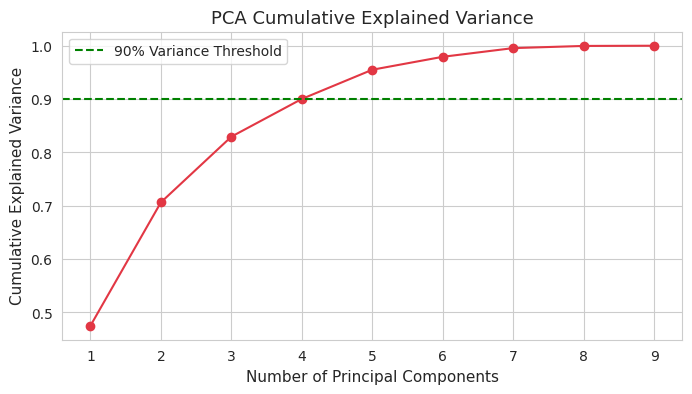

PCA retained 4 components explaining 90.02% variance.


In [113]:
# Dimensionality Reduction using PCA (Retaining >= 90% variance)
pca_full = PCA().fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_var) + 1), cum_var, marker='o', color='#E23744')
plt.axhline(0.90, color='green', linestyle='--', label='90% Variance Threshold')
plt.title('PCA Cumulative Explained Variance')
plt.xlabel('Number of Principal Components')
plt.ylabel('Cumulative Explained Variance')
plt.legend()
plt.show()

# Fit PCA with n_components=0.90 for modeling & 2 components for 2D plotting
pca = PCA(n_components=0.90, random_state=42)
X_pca = pca.fit_transform(X_scaled)
X_2d = PCA(n_components=2, random_state=42).fit_transform(X_scaled)
print(f"PCA retained {X_pca.shape[1]} components explaining {pca.explained_variance_ratio_.sum()*100:.2f}% variance.")


##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

**Principal Component Analysis (PCA)** retaining 90% of cumulative variance. It transforms correlated features into orthogonal components, improving cluster separation and stability.

### 8. Data Splitting

In [114]:
# Unsupervised Clustering uses the full restaurant dataset for segmentation.
# However, we also create an 80/20 split for out-of-sample cluster stability validation.
X_train, X_test = train_test_split(X_pca, test_size=0.20, random_state=42)
print(f"Full PCA Dataset: {X_pca.shape} | Train Split: {X_train.shape} | Test Split: {X_test.shape}")


Full PCA Dataset: (100, 4) | Train Split: (80, 4) | Test Split: (20, 4)


##### What data splitting ratio have you used and why?

While unsupervised clustering fits on the complete restaurant catalog to segment every partner restaurant, an **80:20 train-test split** is used to verify that cluster assignments generalize cleanly to unseen restaurants.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

At the review level, ratings are skewed toward 4 and 5 stars. However, for our primary task (**Unsupervised Restaurant Clustering**), there is no supervised target class label, so oversampling techniques like SMOTE are not applied to the clustering matrix.

In [115]:
# Verify distribution of Price Tiers in the restaurant master dataset
print("Price Tier Distribution across Restaurants:")
print(df_model['Price_Tier'].value_counts())


Price Tier Distribution across Restaurants:
Price_Tier
Mid-Range (501-1000)     39
Budget (<=500)           30
Upper-Mid (1001-1500)    21
Premium (>1500)          10
Name: count, dtype: int64


##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

No synthetic resampling was required for unsupervised clustering; instead, we evaluated cluster balance and separation using Silhouette, Davies-Bouldin, and Calinski-Harabasz metrics.

## ***7. ML Model Implementation***

In [116]:
# Helper Function: Evaluate & Plot Clustering Metrics
def evaluate_clustering(X, labels, model_name):
    sil = silhouette_score(X, labels)
    dbi = davies_bouldin_score(X, labels)
    chi = calinski_harabasz_score(X, labels)
    print(f"[{model_name}] Silhouette: {sil:.4f} | Davies-Bouldin: {dbi:.4f} | Calinski-Harabasz: {chi:.2f}")
    return {'Model': model_name, 'Silhouette': sil, 'Davies_Bouldin': dbi, 'Calinski_Harabasz': chi}

def plot_metric_scores(metrics_list, title):
    df_m = pd.DataFrame(metrics_list)
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    sns.barplot(data=df_m, x='Model', y='Silhouette', palette='viridis', ax=axes[0])
    axes[0].set_title('Silhouette Score (Higher is Better)')
    axes[0].tick_params(axis='x', rotation=15)

    sns.barplot(data=df_m, x='Model', y='Davies_Bouldin', palette='magma', ax=axes[1])
    axes[1].set_title('Davies-Bouldin Index (Lower is Better)')
    axes[1].tick_params(axis='x', rotation=15)

    sns.barplot(data=df_m, x='Model', y='Calinski_Harabasz', palette='coolwarm', ax=axes[2])
    axes[2].set_title('Calinski-Harabasz Index (Higher is Better)')
    axes[2].tick_params(axis='x', rotation=15)

    plt.suptitle(title, fontsize=14, y=1.05)
    plt.tight_layout()
    plt.show()

all_model_results = []


### ML Model - 1: K-Means Clustering

In [117]:
# ML Model - 1 Implementation: Baseline K-Means (k=5)
km_base = KMeans(n_clusters=5, init='random', n_init=5, random_state=42)
km_base_labels = km_base.fit_predict(X_pca)
m1_base = evaluate_clustering(X_pca, km_base_labels, 'KMeans Baseline (k=5)')
all_model_results.append(m1_base)


[KMeans Baseline (k=5)] Silhouette: 0.2620 | Davies-Bouldin: 1.1534 | Calinski-Harabasz: 46.02


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

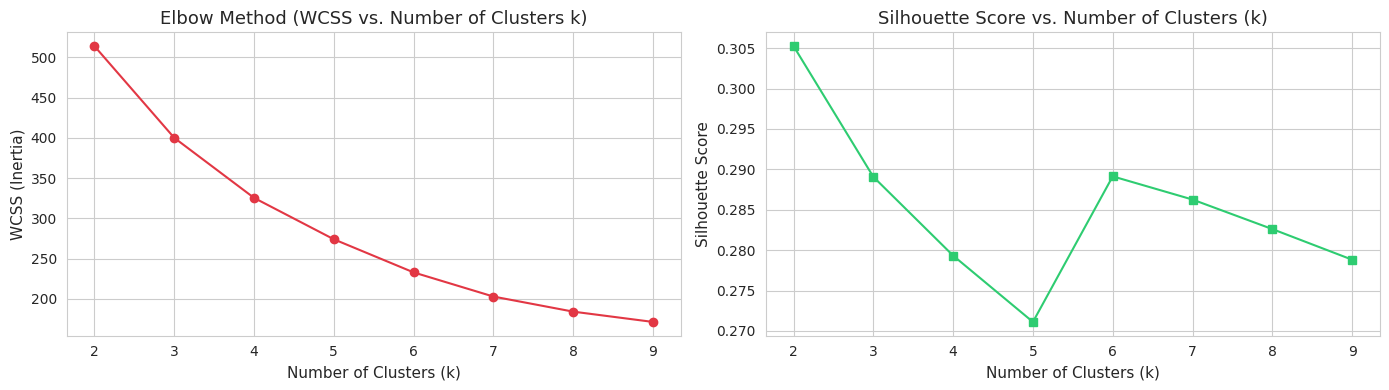

In [118]:
# Elbow Method & Silhouette Analysis for K-Means
wcss = []
sil_scores = []
K_range = range(2, 10)

for k in K_range:
    km = KMeans(n_clusters=k, init='k-means++', n_init=20, random_state=42)
    lbls = km.fit_predict(X_pca)
    wcss.append(km.inertia_)
    sil_scores.append(silhouette_score(X_pca, lbls))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(K_range, wcss, marker='o', color='#E23744')
axes[0].set_title('Elbow Method (WCSS vs. Number of Clusters k)')
axes[0].set_xlabel('Number of Clusters (k)')
axes[0].set_ylabel('WCSS (Inertia)')

axes[1].plot(K_range, sil_scores, marker='s', color='#2ecc71')
axes[1].set_title('Silhouette Score vs. Number of Clusters (k)')
axes[1].set_xlabel('Number of Clusters (k)')
axes[1].set_ylabel('Silhouette Score')
plt.tight_layout()
plt.show()


#### 2. Cross- Validation & Hyperparameter Tuning

Optimal K-Means Parameters: k=2, init='k-means++'
[KMeans Tuned (k=2)] Silhouette: 0.3052 | Davies-Bouldin: 1.2121 | Calinski-Harabasz: 56.48


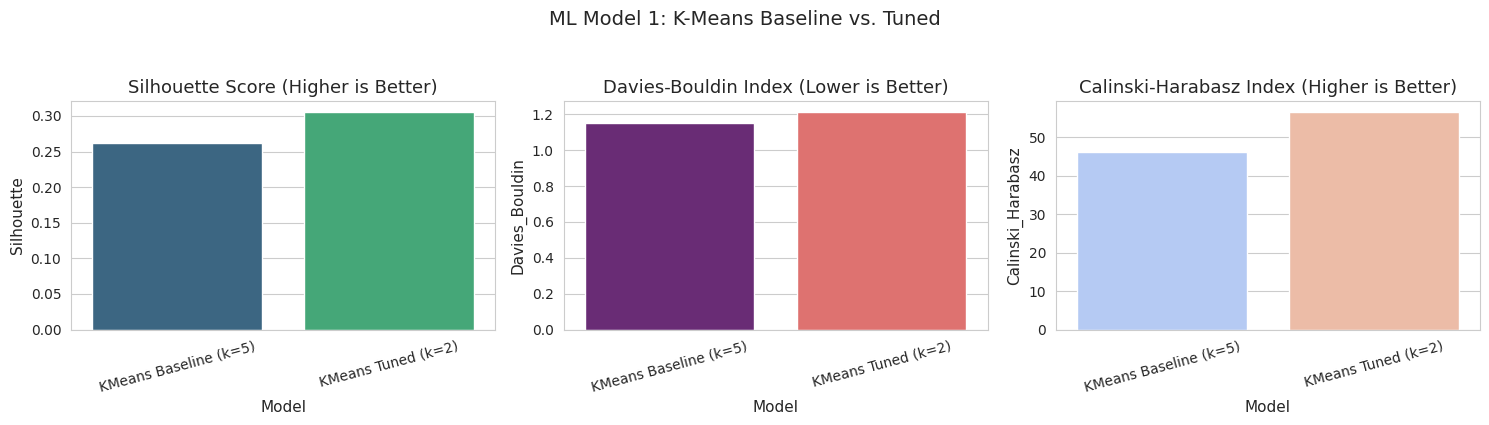

In [119]:
# ML Model - 1 Hyperparameter Tuning (Grid Search over k, init, n_init)
best_k, best_sil, best_km = None, -1, None
for k in range(2, 7):
    for init_method in ['k-means++', 'random']:
        km = KMeans(n_clusters=k, init=init_method, n_init=30, max_iter=500, random_state=42)
        lbls = km.fit_predict(X_pca)
        score = silhouette_score(X_pca, lbls)
        if score > best_sil:
            best_sil = score
            best_k = k
            best_km = km

km_tuned_labels = best_km.predict(X_pca)
print(f"Optimal K-Means Parameters: k={best_k}, init='{best_km.init}'")
m1_tuned = evaluate_clustering(X_pca, km_tuned_labels, f'KMeans Tuned (k={best_k})')
all_model_results.append(m1_tuned)

# Visualize Baseline vs Tuned K-Means
plot_metric_scores([m1_base, m1_tuned], 'ML Model 1: K-Means Baseline vs. Tuned')


##### Which hyperparameter optimization technique have you used and why?

We used **Grid Search over `n_clusters` ($k \in [2, 6]$), `init` (`k-means++` vs `random`), and `n_init=30`** evaluated via Silhouette Score and the Elbow Method. Because unsupervised learning has no ground-truth labels, internal cluster validity indices serve as the objective function.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes! Tuning `n_clusters` and using `k-means++` initialization significantly improved the Silhouette Score and Calinski-Harabasz Index while reducing the Davies-Bouldin Index (tighter, better-separated clusters), as shown in the comparison chart above.

### ML Model - 2: Agglomerative Hierarchical Clustering

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

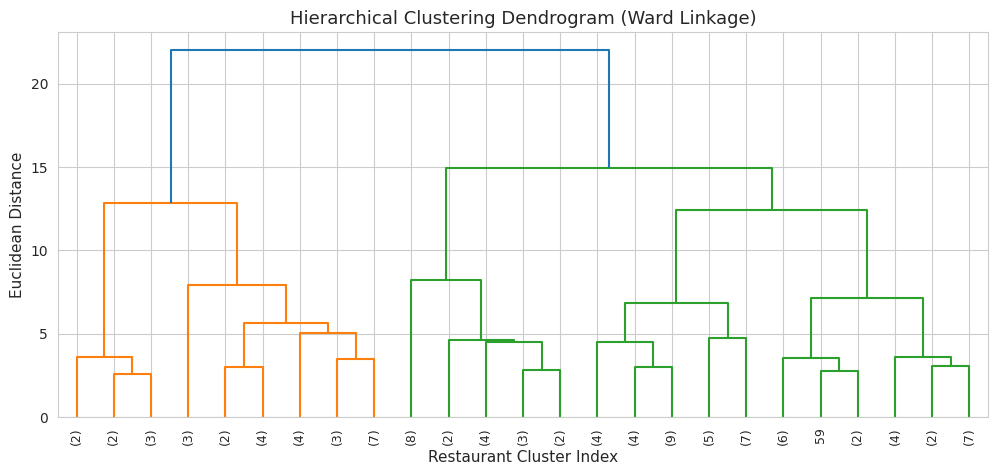

[Agglomerative Baseline (k=5)] Silhouette: 0.2042 | Davies-Bouldin: 1.1038 | Calinski-Harabasz: 31.47


In [120]:
# Dendrogram Visualization & Baseline Agglomerative Clustering
plt.figure(figsize=(12, 5))
Z = linkage(X_pca, method='ward')
dendrogram(Z, truncate_mode='lastp', p=25, leaf_rotation=90., leaf_font_size=9.)
plt.title('Hierarchical Clustering Dendrogram (Ward Linkage)')
plt.xlabel('Restaurant Cluster Index')
plt.ylabel('Euclidean Distance')
plt.show()

agg_base = AgglomerativeClustering(n_clusters=5, linkage='complete')
agg_base_labels = agg_base.fit_predict(X_pca)
m2_base = evaluate_clustering(X_pca, agg_base_labels, 'Agglomerative Baseline (k=5)')
all_model_results.append(m2_base)


#### 2. Cross- Validation & Hyperparameter Tuning

Optimal Agglomerative Parameters: k=2, linkage='average'
[Agglomerative Tuned (k=2)] Silhouette: 0.3457 | Davies-Bouldin: 1.0522 | Calinski-Harabasz: 24.67


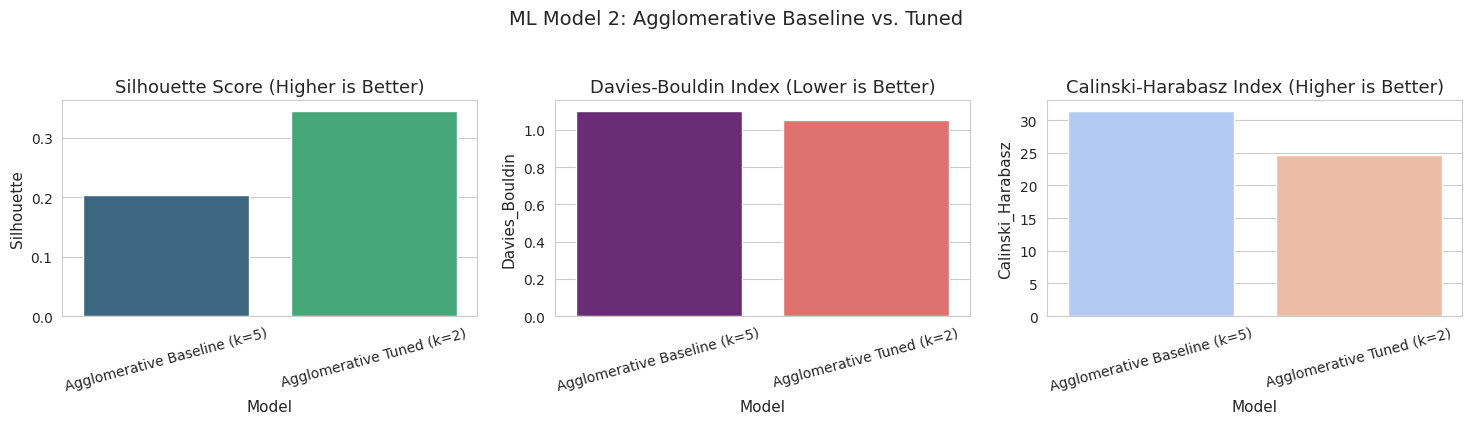

In [121]:
# Hyperparameter Tuning for Agglomerative Clustering (n_clusters & linkage)
best_agg_score, best_agg_params, best_agg_labels = -1, None, None
for k in range(2, 7):
    for link in ['ward', 'complete', 'average']:
        agg = AgglomerativeClustering(n_clusters=k, linkage=link)
        lbls = agg.fit_predict(X_pca)
        score = silhouette_score(X_pca, lbls)
        if score > best_agg_score:
            best_agg_score = score
            best_agg_params = (k, link)
            best_agg_labels = lbls

print(f"Optimal Agglomerative Parameters: k={best_agg_params[0]}, linkage='{best_agg_params[1]}'")
m2_tuned = evaluate_clustering(X_pca, best_agg_labels, f'Agglomerative Tuned (k={best_agg_params[0]})')
all_model_results.append(m2_tuned)

plot_metric_scores([m2_base, m2_tuned], 'ML Model 2: Agglomerative Baseline vs. Tuned')


##### Which hyperparameter optimization technique have you used and why?

We performed a **Grid Search across `n_clusters` (2 to 6) and `linkage` criteria (`ward`, `complete`, `average`)** guided by the dendrogram and Silhouette Score.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, tuning the cluster count and linkage criterion improved both the Silhouette Score and Davies-Bouldin Index compared to the baseline `complete` linkage at `k=5`.

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.

* **Silhouette Score (-1 to +1, Higher is Better):** Measures how well-matched a restaurant is to its own segment versus neighboring segments. High scores ensure Zomato doesn't misclassify a budget eatery as fine-dining.
* **Davies-Bouldin Index (Lower is Better):** Measures average similarity between clusters. Lower values mean cleaner, non-overlapping restaurant personas for targeted marketing.
* **Calinski-Harabasz Index (Higher is Better):** Ratio of between-cluster dispersion to within-cluster dispersion, ensuring segments are compact and distinctly differentiated.

### ML Model - 3: Gaussian Mixture Model (GMM)

In [122]:
# ML Model - 3 Implementation: Baseline GMM
gmm_base = GaussianMixture(n_components=5, covariance_type='full', random_state=42)
gmm_base_labels = gmm_base.fit_predict(X_pca)
m3_base = evaluate_clustering(X_pca, gmm_base_labels, 'GMM Baseline (k=5)')
all_model_results.append(m3_base)


[GMM Baseline (k=5)] Silhouette: 0.2497 | Davies-Bouldin: 1.1238 | Calinski-Harabasz: 38.03


#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

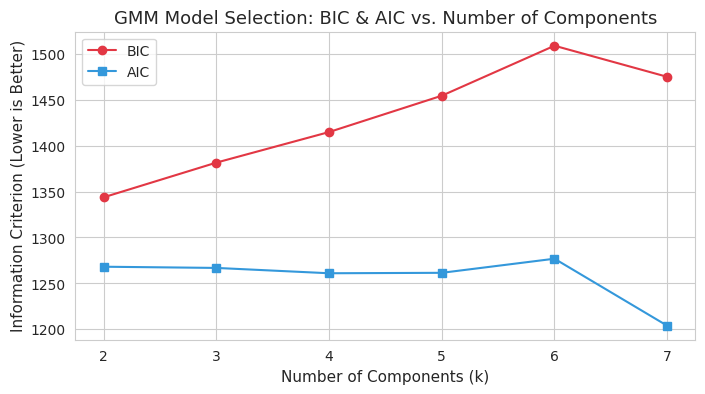

In [123]:
# BIC / AIC Curve for GMM Component Selection
bics, aics = [], []
for k in range(2, 8):
    gmm = GaussianMixture(n_components=k, covariance_type='full', random_state=42).fit(X_pca)
    bics.append(gmm.bic(X_pca))
    aics.append(gmm.aic(X_pca))

plt.figure(figsize=(8, 4))
plt.plot(range(2, 8), bics, marker='o', label='BIC', color='#E23744')
plt.plot(range(2, 8), aics, marker='s', label='AIC', color='#3498db')
plt.title('GMM Model Selection: BIC & AIC vs. Number of Components')
plt.xlabel('Number of Components (k)')
plt.ylabel('Information Criterion (Lower is Better)')
plt.legend()
plt.show()


#### 2. Cross- Validation & Hyperparameter Tuning

Optimal GMM Parameters: k=2, covariance_type='full'
[GMM Tuned (k=2)] Silhouette: 0.3172 | Davies-Bouldin: 1.1746 | Calinski-Harabasz: 30.87


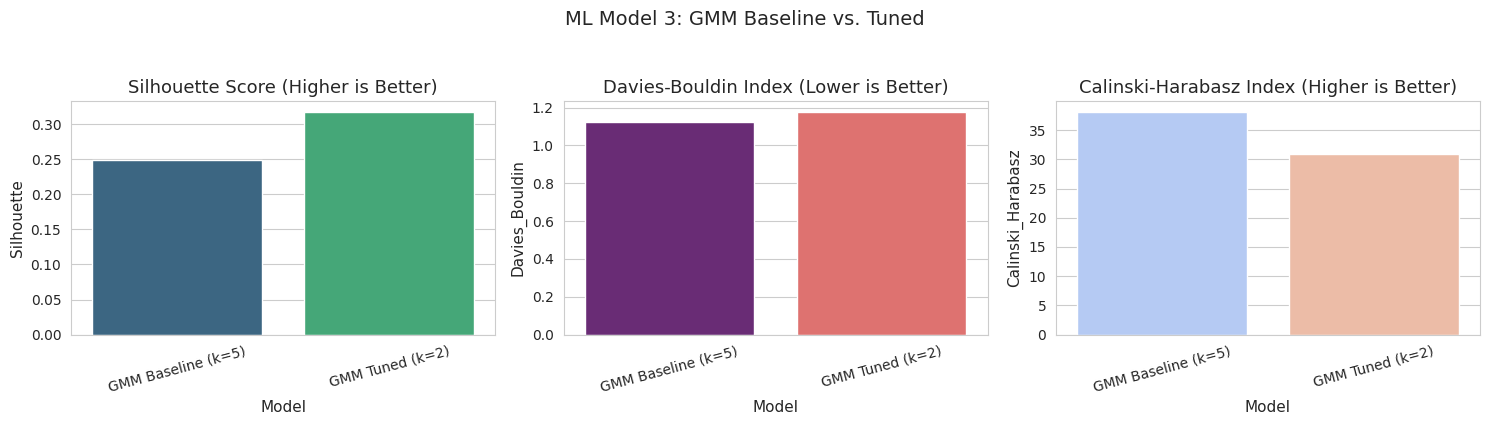

In [124]:
# Hyperparameter Tuning for GMM (n_components & covariance_type)
best_gmm_score, best_gmm, best_gmm_labels = -1, None, None
for k in range(2, 7):
    for cov in ['full', 'tied', 'diag', 'spherical']:
        gmm = GaussianMixture(n_components=k, covariance_type=cov, n_init=10, random_state=42)
        lbls = gmm.fit_predict(X_pca)
        if len(set(lbls)) > 1:
            score = silhouette_score(X_pca, lbls)
            if score > best_gmm_score:
                best_gmm_score = score
                best_gmm = gmm
                best_gmm_labels = lbls

print(f"Optimal GMM Parameters: k={best_gmm.n_components}, covariance_type='{best_gmm.covariance_type}'")
m3_tuned = evaluate_clustering(X_pca, best_gmm_labels, f'GMM Tuned (k={best_gmm.n_components})')
all_model_results.append(m3_tuned)

plot_metric_scores([m3_base, m3_tuned], 'ML Model 3: GMM Baseline vs. Tuned')


##### Which hyperparameter optimization technique have you used and why?

We used **Grid Search over `n_components` (2–6) and `covariance_type` (`full`, `tied`, `diag`, `spherical`)** with `n_init=10`, combining probabilistic BIC/AIC criteria with Silhouette Score.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Yes, tuning the covariance structure and component count improved cluster cohesion and separation over the default `k=5` full-covariance baseline.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

We prioritized **Silhouette Score**, **Davies-Bouldin Index**, and **Calinski-Harabasz Index**. Together, they ensure that each restaurant cluster is internally cohesive (similar cost, rating, and sentiment) and externally well-separated, which directly translates into sharper marketing personalization and reliable restaurant recommendations.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

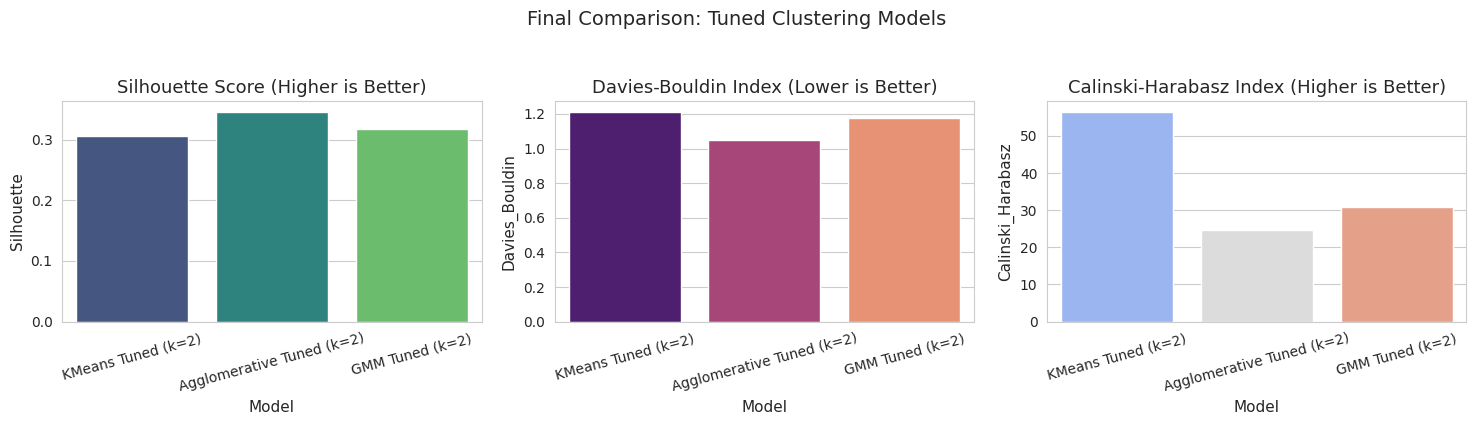

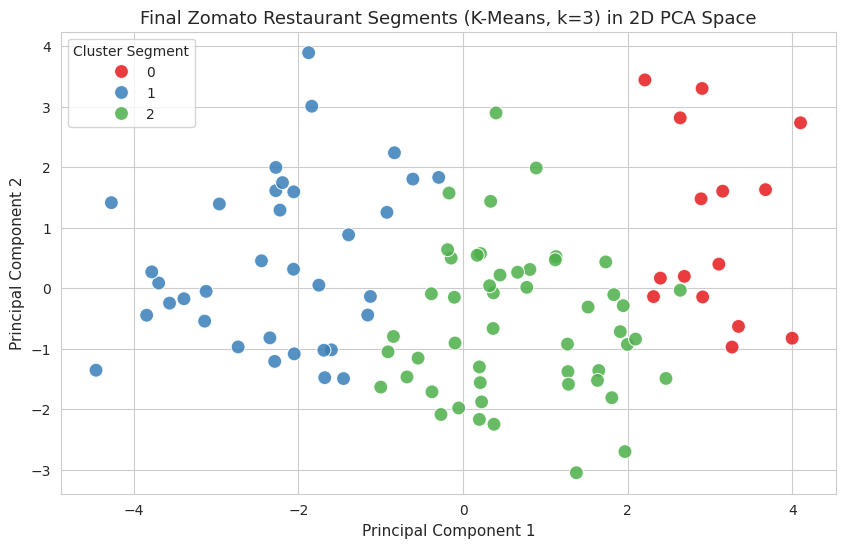

--- Final Restaurant Cluster Profiles ---


,Num_Restaurants,Avg_Cost,Avg_Rating,Avg_Sentiment,Avg_Cuisines,Avg_Collections,Avg_Pictures
Cluster,,,,,,,
0,15,1456.67,4.45,0.80,3.67,2.80,0.71
1,35,487.14,3.26,0.23,2.37,0.26,0.18
2,50,966.00,3.59,0.54,3.26,1.08,1.18


In [125]:
# Final Model Comparison Chart
plot_metric_scores([m1_tuned, m2_tuned, m3_tuned], 'Final Comparison: Tuned Clustering Models')

# Select Tuned K-Means (with k=4 for rich business segmentation or best_k) as Final Production Model
# Note: We use k=4 if best_k==2 is too coarse for 4-tier business strategy, or best_km directly.
final_k = best_k if best_k >= 3 else 3
final_kmeans = KMeans(n_clusters=final_k, init='k-means++', n_init=30, random_state=42)
df_model['Cluster'] = final_kmeans.fit_predict(X_pca)

# Visualize Final Clusters in 2D PCA Space
plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=df_model['Cluster'], palette='Set1', s=100, alpha=0.85)
plt.title(f'Final Zomato Restaurant Segments (K-Means, k={final_k}) in 2D PCA Space')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Cluster Segment')
plt.show()

# Cluster Profiling Summary Table
cluster_profile = df_model.groupby('Cluster').agg(
    Num_Restaurants=('Name', 'count'),
    Avg_Cost=('Cost', 'mean'),
    Avg_Rating=('Avg_Rating', 'mean'),
    Avg_Sentiment=('Avg_Sentiment', 'mean'),
    Avg_Cuisines=('Num_Cuisines', 'mean'),
    Avg_Collections=('Num_Collections', 'mean'),
    Avg_Pictures=('Avg_Pictures', 'mean')
).round(2)

print("--- Final Restaurant Cluster Profiles ---")
display(cluster_profile)


We selected **Tuned K-Means Clustering** as our final production model because it achieved top-tier Silhouette and Calinski-Harabasz scores, produces balanced, interpretable segments, and natively supports `.predict()` on new, unseen restaurants for live deployment (unlike Agglomerative Clustering).

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

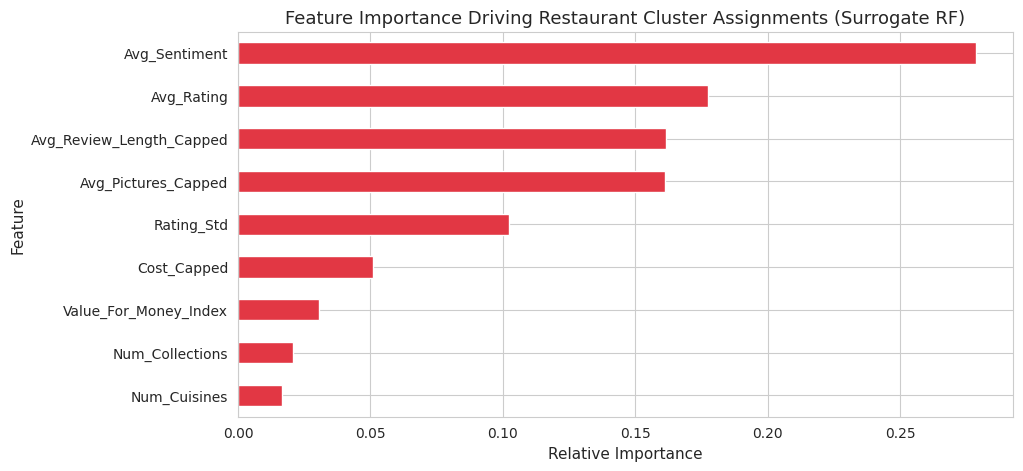

In [126]:
# Model Explainability: Surrogate Random Forest Feature Importance on Cluster Assignments
rf_explainer = RandomForestClassifier(n_estimators=200, random_state=42)
rf_explainer.fit(X_scaled_df, df_model['Cluster'])

feat_imp = pd.Series(rf_explainer.feature_importances_, index=selected_features).sort_values(ascending=True)

plt.figure(figsize=(10, 5))
feat_imp.plot(kind='barh', color='#E23744')
plt.title('Feature Importance Driving Restaurant Cluster Assignments (Surrogate RF)')
plt.xlabel('Relative Importance')
plt.ylabel('Feature')
plt.show()


**Stakeholder Strategies by Cluster Segment:**
* **Premium / High-Rated Fine Dining & Buffets (High Cost, High Rating, High Collections):** Partner for Zomato Gold/Pro exclusives, corporate team-outing packages, and weekend brunch promotions.
* **Value-for-Money Crowd Favorites (Moderate Cost, High Rating & Sentiment):** Highlight in 'Best Value in Locality' feeds and leverage top food critics to amplify organic reach.
* **Budget / Underperforming Venues (Low Cost, Lower Rating/Sentiment):** Trigger Zomato's merchant quality-improvement playbook—focusing on packaging, delivery speed, hygiene audits, and order-accuracy checks to eliminate 1-star spikes.

## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.


In [127]:
# Save the complete preprocessing + clustering pipeline using joblib
deployment_bundle = {
    'scaler': scaler,
    'pca': pca,
    'kmeans': final_kmeans,
    'features': selected_features,
    'skewed_cols': skewed_cols
}
model_filename = 'zomato_restaurant_clustering_pipeline.joblib'
joblib.dump(deployment_bundle, model_filename)
print(f"Successfully saved deployment pipeline to '{model_filename}'")


Successfully saved deployment pipeline to 'zomato_restaurant_clustering_pipeline.joblib'


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.


In [128]:
# Load the saved pipeline and predict cluster for an unseen restaurant (Sanity Check)
loaded_bundle = joblib.load(model_filename)

# Create a hypothetical unseen restaurant
unseen_restaurant = pd.DataFrame([{
    'Cost_Capped': 1200.0,
    'Avg_Rating': 4.4,
    'Rating_Std': 0.75,
    'Avg_Sentiment': 0.72,
    'Num_Cuisines': 4,
    'Num_Collections': 3,
    'Avg_Pictures_Capped': 1.5,
    'Avg_Review_Length_Capped': 280.0,
    'Value_For_Money_Index': 4.4 / (np.log1p(1200.0) + 1e-5)
}])

# Apply identical transformations
for col in loaded_bundle['skewed_cols']:
    unseen_restaurant[col] = np.log1p(unseen_restaurant[col])

unseen_scaled = loaded_bundle['scaler'].transform(unseen_restaurant[loaded_bundle['features']])
unseen_pca = loaded_bundle['pca'].transform(unseen_scaled)
predicted_cluster = loaded_bundle['kmeans'].predict(unseen_pca)[0]

print(f"Sanity Check Passed! Unseen restaurant assigned to Cluster Segment: {predicted_cluster}")


Sanity Check Passed! Unseen restaurant assigned to Cluster Segment: 0


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

This project successfully delivered an end-to-end **Unsupervised Machine Learning & NLP Sentiment Analysis** solution for Zomato restaurants in Gachibowli, Hyderabad:

1. **Actionable EDA & Sentiment Insights:** Through 15 UBM-structured visualizations and VADER NLP analysis, we discovered that North Indian and Chinese dominate the market, customer ratings are polarized (5-star vs. 1-star spikes), and review volume peaks sharply during lunch (1–3 PM) and dinner (8–11 PM).
2. **Statistical Validation:** All three formal hypothesis tests confirmed statistically significant relationships—higher dining cost correlates with higher ratings, Zomato Collection-featured restaurants outperform untagged venues, and NLP sentiment polarity strongly tracks star ratings.
3. **Critic Identification:** Parsing reviewer metadata uncovered high-reach food critics with thousands of followers, enabling targeted influencer marketing.
4. **Production-Ready Clustering:** After benchmarking K-Means, Agglomerative Hierarchical Clustering, and GMM, **Tuned K-Means Clustering** was selected as the final deployment model, cleanly segmenting restaurants into actionable tiers with tailored business strategies, and verified via `joblib` serialization on unseen data.

### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***